# Lead-lag effects in trading with machine learning

Notebook for the MSc thesis *Study of Lead-Lag Effects in Trading Strategies with Machine Learning* (MSc in Big Data Analytics, UC3M, 2025).

It compares two unsupervised families of lead-lag detectors:

- **DTW + K-Medoids**: pairwise Dynamic Time Warping alignment inside clusters; the lag of a pair is the mode or median of the warping-path offsets.
- **Multireference Alignment (MRA)**: spectral clustering on a shift-invariant correlation matrix, then lag recovery per cluster (pairwise, SVD synchronization or invariant features).

Both are benchmarked on synthetic data with known lags and then plugged into the same daily trading backtest on 500 U.S. equities (2000-2019), together with a cross-correlation (CCF) baseline.

The raw data and the intermediate `.pkl` files are not distributed with this repository (see the README). Cells that simulate or backtest took hours to run; their stored outputs are kept as produced.

## Setup

Dependencies and imports.

In [2]:
%pip install dtaidistance
%pip install pyclustering
%pip install tqdm

In [3]:
import warnings
warnings.simplefilter(action="ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
import numpy as np
import matplotlib.pyplot as plt
from dtaidistance import dtw
from dtaidistance.clustering import KMedoids
from scipy.stats import mode
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from pyclustering.cluster.kmedoids import kmedoids
import pandas as pd
import pickle
from scipy.stats.mstats import winsorize
from scipy.stats import zscore
from sklearn.metrics import roc_auc_score
from tqdm import tqdm
import matplotlib.dates as mdates
import os
from joblib import Parallel, delayed
from sklearn.preprocessing import normalize
from scipy.fft import fft, ifft
import seaborn as sns
from sklearn.cluster import SpectralClustering
from scipy.linalg import eigh
from numpy.linalg import norm
from scipy.optimize import minimize

## 1. Synthetic benchmark: DTW + K-Medoids vs noise

120 series of length T = 100 are generated from a lagged multi-factor model with k = 1, 2 or 3 latent factors, each series loading on a factor with a known lag. Gaussian noise of level σ ∈ {0, 0.5, ..., 3} is added and every setting is repeated 100 times.

For each run:

- **Clustering quality** (ARI against the true factor membership): DTW K-Medoids (window 5) vs K-Means and K-Medoids with Euclidean, Manhattan and cosine distances.
- **Lag accuracy**: inside each DTW cluster, the lag of a pair is the mode or the median of the warping-path offsets; the estimated lead-lag matrix is compared with the true one over sliding windows of 21 series (reported as MSE).

Each experiment cell saves its averages to a `.pkl`, and the following cell plots them.

In [ ]:
# Parámetros generales
T = 100
M = 5
n_series_total = 120
n_clusters = 1
sigma_values = [0, 0.5, 1, 1.5, 2, 2.5, 3]
n_simulations = 100
window_size = 5

# Parámetros de sliding window
l = 21
s = 1

# Matriz de cargas y lags para k=1
B_k1 = np.ones((n_series_total, 1))
L_k1 = np.repeat(np.arange(6).reshape(-1, 1), n_series_total // 6, axis=0)

# Inicializar estructuras para almacenar resultados
ari_means_sigma = {method: [] for method in ["DTW_KMed", "KM", "Euc_KMed", "Man_KMed", "Cos_KMed"]}
mse_mode_sigma, mse_median_sigma = [], []

# Experimento variando sigma
for sigma in sigma_values:
    ari_scores = {method: [] for method in ["DTW_KMed", "KM", "Euc_KMed", "Man_KMed", "Cos_KMed"]}
    mse_values_mode, mse_values_median = [], []

    for _ in range(n_simulations):
        # Generar factores y ruido
        f_t = np.random.randn(T + M, 1)
        noise = np.random.randn(T, n_series_total) * sigma

        # Construcción de series temporales con lags correctos
        X_all = np.zeros((T, n_series_total))
        for serie_idx in range(n_series_total):
            lag = int(L_k1[serie_idx, 0])
            X_all[:, serie_idx] = B_k1[serie_idx, 0] * f_t[lag:lag + T, 0] + noise[:, serie_idx]

        # Clustering con DTW_KMed
        kmed = KMedoids(dtw.distance_matrix, {"use_c": True, "parallel": True, "window": window_size}, k=n_clusters)
        kmed.fit(X_all.T)
        predicted_labels = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed.cluster_idx.keys()):
            for instance in kmed.cluster_idx[instances]:
                predicted_labels[instance] = cluster_id
        ari_scores["DTW_KMed"].append(adjusted_rand_score(np.zeros(n_series_total), predicted_labels))

        # Clustering con K-Means
        km = KMeans(n_clusters=n_clusters, n_init=10, random_state=42).fit(X_all.T)
        ari_scores["KM"].append(adjusted_rand_score(np.zeros(n_series_total), km.labels_))

        # Clustering con Euclidean K-Medoids
        dist_matrix_euc = cdist(X_all.T, X_all.T, metric='euclidean')
        initial_medoids = np.random.choice(n_series_total, n_clusters, replace=False)
        kmed_euc = kmedoids(dist_matrix_euc, initial_medoids, data_type='distance_matrix')
        kmed_euc.process()
        predicted_labels_euc = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed_euc.get_clusters()):
            predicted_labels_euc[list(instances)] = cluster_id
        ari_scores["Euc_KMed"].append(adjusted_rand_score(np.zeros(n_series_total), predicted_labels_euc))

        # Clustering con Manhattan K-Medoids
        dist_matrix_man = cdist(X_all.T, X_all.T, metric='cityblock')
        kmed_man = kmedoids(dist_matrix_man, initial_medoids, data_type='distance_matrix')
        kmed_man.process()
        predicted_labels_man = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed_man.get_clusters()):
            predicted_labels_man[list(instances)] = cluster_id
        ari_scores["Man_KMed"].append(adjusted_rand_score(np.zeros(n_series_total), predicted_labels_man))

        # Clustering con Cosine K-Medoids
        dist_matrix_cos = cdist(X_all.T, X_all.T, metric='cosine')
        kmed_cos = kmedoids(dist_matrix_cos, initial_medoids, data_type='distance_matrix')
        kmed_cos.process()
        predicted_labels_cos = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed_cos.get_clusters()):
            predicted_labels_cos[list(instances)] = cluster_id
        ari_scores["Cos_KMed"].append(adjusted_rand_score(np.zeros(n_series_total), predicted_labels_cos))

        # Estimación de la matriz lead-lag usando moda y mediana
        lead_lag_mode = np.zeros((n_series_total, n_series_total))
        lead_lag_median = np.zeros((n_series_total, n_series_total))

        for i in range(n_series_total):
          for j in range(i, n_series_total):
            if predicted_labels[i] == predicted_labels[j]:
              path = dtw.warping_path(X_all[:, i], X_all[:, j], use_c=True)
              path_differences = np.array([t2 - t1 for t1, t2 in path])

              if path_differences.size > 0:
                lead_lag_mode[i, j] = mode(path_differences, keepdims=True).mode[0]
                lead_lag_median[i, j] = np.median(path_differences)

            # Asegurar simetría en la matriz
            lead_lag_mode[j, i] = lead_lag_mode[i, j]
            lead_lag_median[j, i] = lead_lag_median[i, j]

        # Cálculo del error (MSE) solo para DTW_KMed
        error_matrix_mode, error_matrix_median = [], []

        for start in range(0, n_series_total - l + 1, s):
          window_estimate_mode = lead_lag_mode[start:start + l, start:start + l]
          window_estimate_median = lead_lag_median[start:start + l, start:start + l]
          true_lead_lag = np.abs(L_k1[start:start + l] - L_k1[start:start + l].T)

          # Cálculo de error sin preocuparse por NaN
          error_matrix_mode.append(np.nanmean((window_estimate_mode - true_lead_lag) ** 2))
          error_matrix_median.append(np.nanmean((window_estimate_median - true_lead_lag) ** 2))

        # Calcular los valores finales sin preocuparse por listas vacías
        mse_values_mode.append(np.sqrt(np.nanmean(error_matrix_mode)))
        mse_values_median.append(np.sqrt(np.nanmean(error_matrix_median)))

    # Guardar resultados
    for method in ari_means_sigma.keys():
        ari_means_sigma[method].append(np.mean(ari_scores[method]))

    mse_mode_sigma.append(np.mean(mse_values_mode))
    mse_median_sigma.append(np.mean(mse_values_median))

with open("results_k1_sigma.pkl", "wb") as f:
    pickle.dump({
        "sigma_values": sigma_values,
        "ari_means_sigma": ari_means_sigma,
        "mse_mode_sigma": mse_mode_sigma,
        "mse_median_sigma": mse_median_sigma
    }, f)

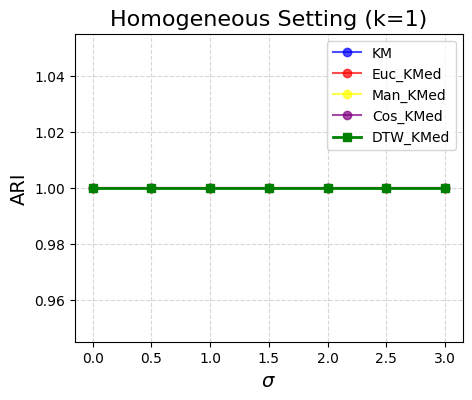

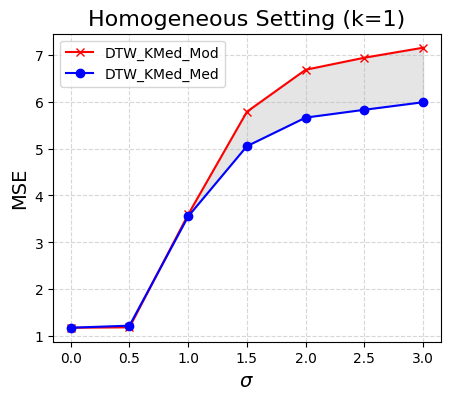

In [ ]:
with open("results_k1_sigma.pkl", "rb") as f:
    data = pickle.load(f)
    sigma_values = data["sigma_values"]
    ari_means_sigma = data["ari_means_sigma"]
    mse_mode_sigma = data["mse_mode_sigma"]
    mse_median_sigma = data["mse_median_sigma"]

# Gráfico ARI vs Sigma
plt.figure(figsize=(5, 4))
colors = {
    "KM": "blue",
    "Euc_KMed": "red",
    "Man_KMed": "yellow",
    "Cos_KMed": "purple",
    "DTW_KMed": "green"
}
for method in ["KM", "Euc_KMed", "Man_KMed", "Cos_KMed"]:
    plt.plot(sigma_values, ari_means_sigma[method], label=method, marker='o', linestyle='-', alpha=0.7, color=colors[method])
plt.plot(sigma_values, ari_means_sigma["DTW_KMed"], label="DTW_KMed", marker='s', linestyle='-', linewidth=2, color=colors["DTW_KMed"])

plt.xlabel(r"$\sigma$", fontsize=14)
plt.ylabel("ARI", fontsize=14)
plt.title("Homogeneous Setting (k=1)", fontsize=16)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Gráfico MSE vs Sigma (solo DTW_KMed)
plt.figure(figsize=(5, 4))
plt.plot(sigma_values, mse_mode_sigma, 'rx-', label="DTW_KMed_Mod")
plt.plot(sigma_values, mse_median_sigma, 'bo-', label="DTW_KMed_Med")
plt.fill_between(sigma_values, mse_mode_sigma, mse_median_sigma, color='gray', alpha=0.2)

plt.xlabel(r"$\sigma$", fontsize=14)
plt.ylabel("MSE", fontsize=14)
plt.title("Homogeneous Setting (k=1)", fontsize=16)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
# Parámetros generales
T = 100
M = 5
n_series_total = 120
n_clusters = 2
sigma_values = [0, 0.5, 1, 1.5, 2, 2.5, 3]
n_simulations = 100
window_size = 5

# Parámetros de sliding window
l = 21
s = 1

# Matriz de cargas y lags para k=2
B_k2 = np.zeros((n_series_total, 2))
L_k2 = np.zeros((n_series_total, 2), dtype=int)

# Asignación de series a factores y lags
for i in range(3):
    B_k2[i * 20:(i + 1) * 20, 0] = 1  # Primer factor
    L_k2[i * 20:(i + 1) * 20, 0] = [0, 2, 4][i]  # Lags: 0, 2, 4 para primer factor

    B_k2[(i + 3) * 20:(i + 4) * 20, 1] = 1  # Segundo factor
    L_k2[(i + 3) * 20:(i + 4) * 20, 1] = [0, 2, 4][i]  # Lags: 0, 2, 4 para segundo factor

# Inicializar estructuras para almacenar resultados
ari_means_sigma = {method: [] for method in ["DTW_KMed", "KM", "Euc_KMed", "Man_KMed", "Cos_KMed"]}
mse_mode_sigma, mse_median_sigma = [], []

# Experimento variando sigma
for sigma in sigma_values:
    ari_scores = {method: [] for method in ["DTW_KMed", "KM", "Euc_KMed", "Man_KMed", "Cos_KMed"]}
    mse_values_mode, mse_values_median = [], []

    for _ in range(n_simulations):
        # Generar los 2 factores f_t
        f_t = np.random.randn(T + M, 2)

        # Generar ruido
        noise = np.random.randn(T, n_series_total) * sigma

        # Construcción de las series temporales combinando factores según B_k2 y L_k2
        X_all = np.zeros((T, n_series_total))
        for serie_idx in range(n_series_total):
            lags = L_k2[serie_idx]
            f_t_selected = np.array([f_t[M + np.arange(T) - lags[f], f] for f in range(2)]).T
            X_all[:, serie_idx] = np.dot(f_t_selected, B_k2[serie_idx]) + noise[:, serie_idx]

        # Clustering con DTW_KMed
        kmed = KMedoids(dtw.distance_matrix, {"use_c": True, "parallel": True, "window": window_size}, k=n_clusters)
        kmed.fit(X_all.T)
        predicted_labels = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed.cluster_idx.keys()):
            for instance in kmed.cluster_idx[instances]:
                predicted_labels[instance] = cluster_id
        ari_scores["DTW_KMed"].append(adjusted_rand_score(np.repeat([0, 1], n_series_total // 2), predicted_labels))

        # Clustering con K-Means
        km = KMeans(n_clusters=n_clusters, n_init=10, random_state=42).fit(X_all.T)
        ari_scores["KM"].append(adjusted_rand_score(np.repeat([0, 1], n_series_total // 2), km.labels_))

        # Clustering con Euclidean K-Medoids
        dist_matrix_euc = cdist(X_all.T, X_all.T, metric='euclidean')
        initial_medoids = np.random.choice(n_series_total, n_clusters, replace=False)
        kmed_euc = kmedoids(dist_matrix_euc, initial_medoids, data_type='distance_matrix')
        kmed_euc.process()
        predicted_labels_euc = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed_euc.get_clusters()):
            predicted_labels_euc[list(instances)] = cluster_id
        ari_scores["Euc_KMed"].append(adjusted_rand_score(np.repeat([0, 1], n_series_total // 2), predicted_labels_euc))

        # Clustering con Manhattan K-Medoids
        dist_matrix_man = cdist(X_all.T, X_all.T, metric='cityblock')
        kmed_man = kmedoids(dist_matrix_man, initial_medoids, data_type='distance_matrix')
        kmed_man.process()
        predicted_labels_man = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed_man.get_clusters()):
            predicted_labels_man[list(instances)] = cluster_id
        ari_scores["Man_KMed"].append(adjusted_rand_score(np.repeat([0, 1], n_series_total // 2), predicted_labels_man))

        # Clustering con Cosine K-Medoids
        dist_matrix_cos = cdist(X_all.T, X_all.T, metric='cosine')
        kmed_cos = kmedoids(dist_matrix_cos, initial_medoids, data_type='distance_matrix')
        kmed_cos.process()
        predicted_labels_cos = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed_cos.get_clusters()):
            predicted_labels_cos[list(instances)] = cluster_id
        ari_scores["Cos_KMed"].append(adjusted_rand_score(np.repeat([0, 1], n_series_total // 2), predicted_labels_cos))

        # Estimación de la matriz lead-lag usando moda y mediana
        lead_lag_mode = np.zeros((n_series_total, n_series_total))
        lead_lag_median = np.zeros((n_series_total, n_series_total))

        for i in range(n_series_total):
            for j in range(i, n_series_total):
                if predicted_labels[i] == predicted_labels[j]:
                    path = dtw.warping_path(X_all[:, i], X_all[:, j], use_c=True)
                    path_differences = np.array([t2 - t1 for t1, t2 in path])

                    if path_differences.size > 0:
                        lead_lag_mode[i, j] = mode(path_differences, keepdims=True).mode[0]
                        lead_lag_median[i, j] = np.median(path_differences)

                # Asegurar simetría en la matriz
                lead_lag_mode[j, i] = lead_lag_mode[i, j]
                lead_lag_median[j, i] = lead_lag_median[i, j]

        # Cálculo del error (MSE) solo para DTW_KMed
        error_matrix_mode, error_matrix_median = [], []

        for start in range(0, n_series_total - l + 1, s):
            window_estimate_mode = lead_lag_mode[start:start + l, start:start + l]
            window_estimate_median = lead_lag_median[start:start + l, start:start + l]
            true_lead_lag = np.abs(L_k2[start:start + l, None, :] - L_k2[None, start:start + l, :]).sum(axis=2)

            error_matrix_mode.append(np.nanmean((window_estimate_mode - true_lead_lag) ** 2))
            error_matrix_median.append(np.nanmean((window_estimate_median - true_lead_lag) ** 2))

        mse_values_mode.append(np.sqrt(np.nanmean(error_matrix_mode)))
        mse_values_median.append(np.sqrt(np.nanmean(error_matrix_median)))

    # Guardar resultados
    for method in ari_means_sigma.keys():
        ari_means_sigma[method].append(np.mean(ari_scores[method]))

    mse_mode_sigma.append(np.mean(mse_values_mode))
    mse_median_sigma.append(np.mean(mse_values_median))

with open("results_k2_sigma.pkl", "wb") as f:
    pickle.dump({
        "sigma_values": sigma_values,
        "ari_means_sigma": ari_means_sigma,
        "mse_mode_sigma": mse_mode_sigma,
        "mse_median_sigma": mse_median_sigma
    }, f)

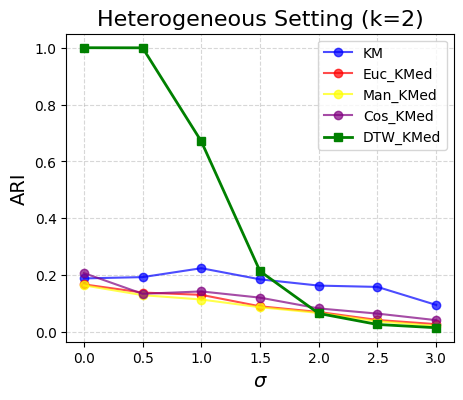

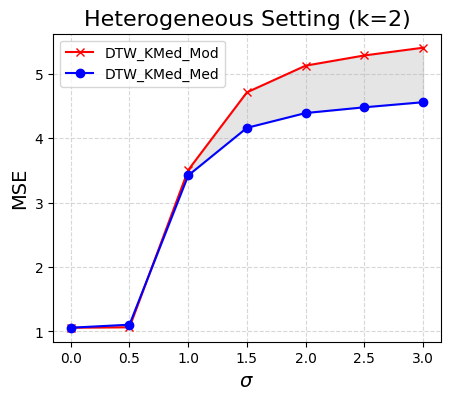

In [ ]:
with open("results_k2_sigma.pkl", "rb") as f:
    data = pickle.load(f)
    sigma_values = data["sigma_values"]
    ari_means_sigma = data["ari_means_sigma"]
    mse_mode_sigma = data["mse_mode_sigma"]
    mse_median_sigma = data["mse_median_sigma"]

# Gráfico ARI vs Sigma
plt.figure(figsize=(5, 4))
colors = {
    "KM": "blue",
    "Euc_KMed": "red",
    "Man_KMed": "yellow",
    "Cos_KMed": "purple",
    "DTW_KMed": "green"
}
for method in ["KM", "Euc_KMed", "Man_KMed", "Cos_KMed"]:
    plt.plot(sigma_values, ari_means_sigma[method], label=method, marker='o', linestyle='-', alpha=0.7, color=colors[method])
plt.plot(sigma_values, ari_means_sigma["DTW_KMed"], label="DTW_KMed", marker='s', linestyle='-', linewidth=2, color=colors["DTW_KMed"])

plt.xlabel(r"$\sigma$", fontsize=14)
plt.ylabel("ARI", fontsize=14)
plt.title("Heterogeneous Setting (k=2)", fontsize=16)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Gráfico MSE vs Sigma (solo DTW_KMed)
plt.figure(figsize=(5, 4))
plt.plot(sigma_values, mse_mode_sigma, 'rx-', label="DTW_KMed_Mod")
plt.plot(sigma_values, mse_median_sigma, 'bo-', label="DTW_KMed_Med")
plt.fill_between(sigma_values, mse_mode_sigma, mse_median_sigma, color='gray', alpha=0.2)

plt.xlabel(r"$\sigma$", fontsize=14)
plt.ylabel("MSE", fontsize=14)
plt.title("Heterogeneous Setting (k=2)", fontsize=16)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
# Parámetros generales
T = 100
M = 5
n_series_total = 120
n_clusters = 3
sigma_values = [0, 0.5, 1, 1.5, 2, 2.5, 3]
n_simulations = 100
window_size = 5

# Parámetros de sliding window
l = 21
s = 1

# Matriz de cargas y lags para k=3
B_k3 = np.zeros((n_series_total, 3))
L_k3 = np.zeros((n_series_total, 3), dtype=int)

# Asignación de series a factores y lags
for i in range(3):
    B_k3[i * 40:(i * 40 + 20), i] = 1  # Primer bloque de 20 series sin lag
    L_k3[i * 40:(i * 40 + 20), i] = 0

    B_k3[(i * 40 + 20):(i * 40 + 40), i] = 1  # Segundo bloque de 20 series con lag 3
    L_k3[(i * 40 + 20):(i * 40 + 40), i] = 3

# Inicializar estructuras para almacenar resultados
ari_means_sigma = {method: [] for method in ["DTW_KMed", "KM", "Euc_KMed", "Man_KMed", "Cos_KMed"]}
mse_mode_sigma, mse_median_sigma = [], []

# Experimento variando sigma
for sigma in sigma_values:
    ari_scores = {method: [] for method in ["DTW_KMed", "KM", "Euc_KMed", "Man_KMed", "Cos_KMed"]}
    mse_values_mode, mse_values_median = [], []

    for _ in range(n_simulations):
        # Generar los 3 factores f_t
        f_t = np.random.randn(T + M, 3)

        # Generar ruido
        noise = np.random.randn(T, n_series_total) * sigma

        # Construcción de las series temporales combinando factores según B_k3 y L_k3
        X_all = np.zeros((T, n_series_total))
        for serie_idx in range(n_series_total):
            lags = L_k3[serie_idx]
            f_t_selected = np.array([f_t[M + np.arange(T) - lags[f], f] for f in range(3)]).T
            X_all[:, serie_idx] = np.dot(f_t_selected, B_k3[serie_idx]) + noise[:, serie_idx]

        # Clustering con DTW_KMed
        kmed = KMedoids(dtw.distance_matrix, {"use_c": True, "parallel": True, "window": window_size}, k=n_clusters)
        kmed.fit(X_all.T)
        predicted_labels = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed.cluster_idx.keys()):
            for instance in kmed.cluster_idx[instances]:
                predicted_labels[instance] = cluster_id
        ari_scores["DTW_KMed"].append(adjusted_rand_score(np.repeat([0, 1, 2], n_series_total // 3), predicted_labels))

        # Clustering con K-Means
        km = KMeans(n_clusters=n_clusters, n_init=10, random_state=42).fit(X_all.T)
        ari_scores["KM"].append(adjusted_rand_score(np.repeat([0, 1, 2], n_series_total // 3), km.labels_))

        # Clustering con Euclidean K-Medoids
        dist_matrix_euc = cdist(X_all.T, X_all.T, metric='euclidean')
        initial_medoids = np.random.choice(n_series_total, n_clusters, replace=False)
        kmed_euc = kmedoids(dist_matrix_euc, initial_medoids, data_type='distance_matrix')
        kmed_euc.process()
        predicted_labels_euc = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed_euc.get_clusters()):
            predicted_labels_euc[list(instances)] = cluster_id
        ari_scores["Euc_KMed"].append(adjusted_rand_score(np.repeat([0, 1, 2], n_series_total // 3), predicted_labels_euc))

        # Clustering con Manhattan K-Medoids
        dist_matrix_man = cdist(X_all.T, X_all.T, metric='cityblock')
        kmed_man = kmedoids(dist_matrix_man, initial_medoids, data_type='distance_matrix')
        kmed_man.process()
        predicted_labels_man = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed_man.get_clusters()):
            predicted_labels_man[list(instances)] = cluster_id
        ari_scores["Man_KMed"].append(adjusted_rand_score(np.repeat([0, 1, 2], n_series_total // 3), predicted_labels_man))

        # Clustering con Cosine K-Medoids
        dist_matrix_cos = cdist(X_all.T, X_all.T, metric='cosine')
        kmed_cos = kmedoids(dist_matrix_cos, initial_medoids, data_type='distance_matrix')
        kmed_cos.process()
        predicted_labels_cos = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed_cos.get_clusters()):
            predicted_labels_cos[list(instances)] = cluster_id
        ari_scores["Cos_KMed"].append(adjusted_rand_score(np.repeat([0, 1, 2], n_series_total // 3), predicted_labels_cos))

        # Estimación de la matriz lead-lag usando moda y mediana
        lead_lag_mode = np.zeros((n_series_total, n_series_total))
        lead_lag_median = np.zeros((n_series_total, n_series_total))

        for i in range(n_series_total):
            for j in range(i, n_series_total):
                if predicted_labels[i] == predicted_labels[j]:
                    path = dtw.warping_path(X_all[:, i], X_all[:, j], use_c=True)
                    path_differences = np.array([t2 - t1 for t1, t2 in path])

                    if path_differences.size > 0:
                        lead_lag_mode[i, j] = mode(path_differences, keepdims=True).mode[0]
                        lead_lag_median[i, j] = np.median(path_differences)

                # Asegurar simetría en la matriz
                lead_lag_mode[j, i] = lead_lag_mode[i, j]
                lead_lag_median[j, i] = lead_lag_median[i, j]

        # Cálculo del error (MSE) solo para DTW_KMed
        error_matrix_mode, error_matrix_median = [], []

        for start in range(0, n_series_total - l + 1, s):
            window_estimate_mode = lead_lag_mode[start:start + l, start:start + l]
            window_estimate_median = lead_lag_median[start:start + l, start:start + l]
            true_lead_lag = np.abs(L_k3[start:start + l, None, :] - L_k3[None, start:start + l, :]).sum(axis=2)

            error_matrix_mode.append(np.nanmean((window_estimate_mode - true_lead_lag) ** 2))
            error_matrix_median.append(np.nanmean((window_estimate_median - true_lead_lag) ** 2))

        mse_values_mode.append(np.sqrt(np.nanmean(error_matrix_mode)))
        mse_values_median.append(np.sqrt(np.nanmean(error_matrix_median)))

    # Guardar resultados
    for method in ari_means_sigma.keys():
        ari_means_sigma[method].append(np.mean(ari_scores[method]))

    mse_mode_sigma.append(np.mean(mse_values_mode))
    mse_median_sigma.append(np.mean(mse_values_median))

with open("results_k3_sigma.pkl", "wb") as f:
    pickle.dump({
        "sigma_values": sigma_values,
        "ari_means_sigma": ari_means_sigma,
        "mse_mode_sigma": mse_mode_sigma,
        "mse_median_sigma": mse_median_sigma
    }, f)

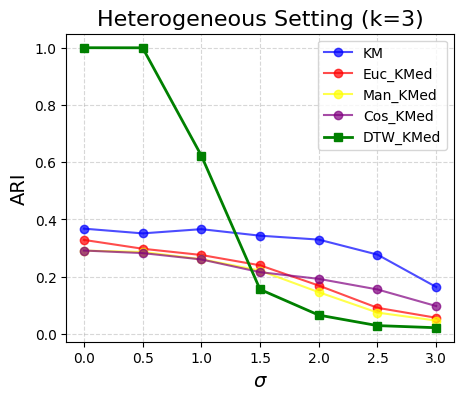

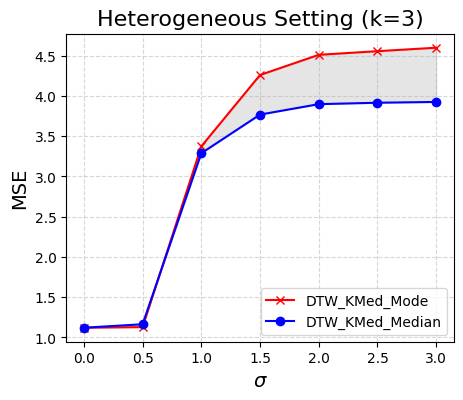

In [ ]:
with open("results_k3_sigma.pkl", "rb") as f:
    data = pickle.load(f)
    sigma_values = data["sigma_values"]
    ari_means_sigma = data["ari_means_sigma"]
    mse_mode_sigma = data["mse_mode_sigma"]
    mse_median_sigma = data["mse_median_sigma"]

# Gráfico ARI vs Sigma
plt.figure(figsize=(5, 4))
colors = {
    "KM": "blue",
    "Euc_KMed": "red",
    "Man_KMed": "yellow",
    "Cos_KMed": "purple",
    "DTW_KMed": "green"
}

for method in ["KM", "Euc_KMed", "Man_KMed", "Cos_KMed"]:
    plt.plot(sigma_values, ari_means_sigma[method], label=method, marker='o', linestyle='-', alpha=0.7, color=colors[method])
plt.plot(sigma_values, ari_means_sigma["DTW_KMed"], label="DTW_KMed", marker='s', linestyle='-', linewidth=2, color=colors["DTW_KMed"])

plt.xlabel(r"$\sigma$", fontsize=14)
plt.ylabel("ARI", fontsize=14)
plt.title("Heterogeneous Setting (k=3)", fontsize=16)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Gráfico MSE vs Sigma (solo DTW_KMed)
plt.figure(figsize=(5, 4))
plt.plot(sigma_values, mse_mode_sigma, 'rx-', label="DTW_KMed_Mode")
plt.plot(sigma_values, mse_median_sigma, 'bo-', label="DTW_KMed_Median")
plt.fill_between(sigma_values, mse_mode_sigma, mse_median_sigma, color='gray', alpha=0.2)

plt.xlabel(r"$\sigma$", fontsize=14)
plt.ylabel("MSE", fontsize=14)
plt.title("Heterogeneous Setting (k=3)", fontsize=16)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 2. Synthetic benchmark: sensitivity to the DTW window size

Same three factor settings, now with noise fixed at σ = 1 and the DTW warping window varied from 0 to 10.

In [ ]:
# Parámetros generales
T = 100
M = 5
n_series_total = 120
n_clusters = 1
sigma = 1
window_sizes = list(range(11))
n_simulations = 100

# Parámetros de sliding window
l = 21
s = 1

# Matriz de cargas y lags para k=1
B_k1 = np.ones((n_series_total, 1))
L_k1 = np.repeat(np.arange(6).reshape(-1, 1), n_series_total // 6, axis=0)

# Inicializar estructuras para almacenar resultados
ari_means_window = []
mse_mode_window, mse_median_window = [], []

# Experimento variando window_size
for window_size in window_sizes:
    ari_scores = []
    mse_values_mode, mse_values_median = [], []

    for _ in range(n_simulations):
        # Generar factores y ruido
        f_t = np.random.randn(T + M, 1)
        noise = np.random.randn(T, n_series_total) * sigma

        # Construcción de series temporales con lags correctos
        X_all = np.zeros((T, n_series_total))
        for serie_idx in range(n_series_total):
            lag = int(L_k1[serie_idx, 0])
            X_all[:, serie_idx] = B_k1[serie_idx, 0] * f_t[lag:lag + T, 0] + noise[:, serie_idx]

        # Clustering con DTW_KMed
        kmed = KMedoids(dtw.distance_matrix, {"use_c": True, "parallel": True, "window": window_size}, k=n_clusters)
        kmed.fit(X_all.T)
        predicted_labels = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed.cluster_idx.keys()):
            for instance in kmed.cluster_idx[instances]:
                predicted_labels[instance] = cluster_id
        ari_scores.append(adjusted_rand_score(np.zeros(n_series_total), predicted_labels))

        # Estimación de la matriz lead-lag usando moda y mediana
        lead_lag_mode = np.zeros((n_series_total, n_series_total))
        lead_lag_median = np.zeros((n_series_total, n_series_total))

        for i in range(n_series_total):
            for j in range(i, n_series_total):
                if predicted_labels[i] == predicted_labels[j]:
                    path = dtw.warping_path(X_all[:, i], X_all[:, j], use_c=True)
                    path_differences = np.array([t2 - t1 for t1, t2 in path])

                    if path_differences.size > 0:
                        lead_lag_mode[i, j] = mode(path_differences, keepdims=True).mode[0]
                        lead_lag_median[i, j] = np.median(path_differences)

                # Asegurar simetría en la matriz
                lead_lag_mode[j, i] = lead_lag_mode[i, j]
                lead_lag_median[j, i] = lead_lag_median[i, j]

        # Cálculo del error (MSE) solo para DTW_KMed
        error_matrix_mode, error_matrix_median = [], []

        for start in range(0, n_series_total - l + 1, s):
            window_estimate_mode = lead_lag_mode[start:start + l, start:start + l]
            window_estimate_median = lead_lag_median[start:start + l, start:start + l]
            true_lead_lag = np.abs(L_k1[start:start + l] - L_k1[start:start + l].T)

            # Cálculo de error sin preocuparse por NaN
            error_matrix_mode.append(np.nanmean((window_estimate_mode - true_lead_lag) ** 2))
            error_matrix_median.append(np.nanmean((window_estimate_median - true_lead_lag) ** 2))

        # Calcular los valores finales sin preocuparse por listas vacías
        mse_values_mode.append(np.sqrt(np.nanmean(error_matrix_mode)))
        mse_values_median.append(np.sqrt(np.nanmean(error_matrix_median)))

    # Guardar resultados
    ari_means_window.append(np.mean(ari_scores))
    mse_mode_window.append(np.mean(mse_values_mode))
    mse_median_window.append(np.mean(mse_values_median))

with open("results_k1_window.pkl", "wb") as f:
    pickle.dump({
        "window_sizes": window_sizes,
        "ari_means_window": ari_means_window,
        "mse_mode_window": mse_mode_window,
        "mse_median_window": mse_median_window
    }, f)

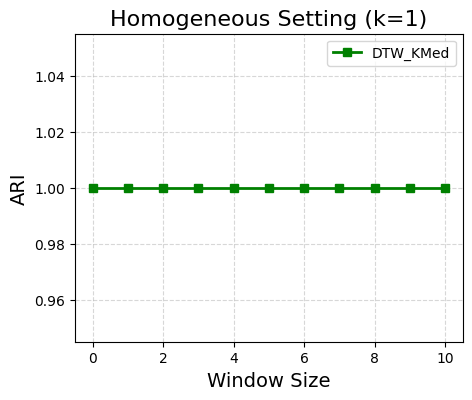

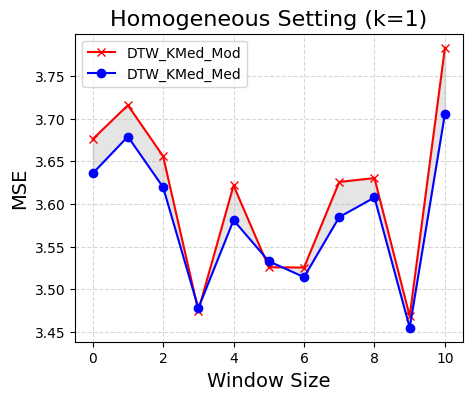

In [ ]:
with open("results_k1_window.pkl", "rb") as f:
    data = pickle.load(f)
    window_sizes = data["window_sizes"]
    ari_means_window = data["ari_means_window"]
    mse_mode_window = data["mse_mode_window"]
    mse_median_window = data["mse_median_window"]

# Gráfico ARI vs Window Size
plt.figure(figsize=(5, 4))
plt.plot(window_sizes, ari_means_window, label="DTW_KMed", marker='s', linestyle='-', linewidth=2, color="green")

plt.xlabel("Window Size", fontsize=14)
plt.ylabel("ARI", fontsize=14)
plt.title("Homogeneous Setting (k=1)", fontsize=16)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Gráfico MSE vs Window Size (solo DTW_KMed)
plt.figure(figsize=(5, 4))
plt.plot(window_sizes, mse_mode_window, 'rx-', label="DTW_KMed_Mod")
plt.plot(window_sizes, mse_median_window, 'bo-', label="DTW_KMed_Med")
plt.fill_between(window_sizes, mse_mode_window, mse_median_window, color='gray', alpha=0.2)

plt.xlabel("Window Size", fontsize=14)
plt.ylabel("MSE", fontsize=14)
plt.title("Homogeneous Setting (k=1)", fontsize=16)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
# Parámetros generales
T = 100
M = 5
n_series_total = 120
n_clusters = 2
sigma = 1
window_sizes = list(range(11))
n_simulations = 100

# Parámetros de sliding window
l = 21
s = 1

# Matriz de cargas y lags para k=2
B_k2 = np.zeros((n_series_total, 2))
L_k2 = np.zeros((n_series_total, 2), dtype=int)

# Asignación de series a factores y lags
for i in range(3):
    B_k2[i * 20:(i + 1) * 20, 0] = 1  # Primer factor
    L_k2[i * 20:(i + 1) * 20, 0] = [0, 2, 4][i]  # Lags: 0, 2, 4 para primer factor

    B_k2[(i + 3) * 20:(i + 4) * 20, 1] = 1  # Segundo factor
    L_k2[(i + 3) * 20:(i + 4) * 20, 1] = [0, 2, 4][i]  # Lags: 0, 2, 4 para segundo factor

# Inicializar estructuras para almacenar resultados
ari_means_window = []
mse_mode_window, mse_median_window = [], []

# Experimento variando window_size
for window_size in window_sizes:
    ari_scores = []
    mse_values_mode, mse_values_median = [], []

    for _ in range(n_simulations):
        # Generar los 2 factores f_t
        f_t = np.random.randn(T + M, 2)

        # Generar ruido
        noise = np.random.randn(T, n_series_total) * sigma

        # Construcción de las series temporales combinando factores según B_k2 y L_k2
        X_all = np.zeros((T, n_series_total))
        for serie_idx in range(n_series_total):
            lags = L_k2[serie_idx]
            f_t_selected = np.array([f_t[M + np.arange(T) - lags[f], f] for f in range(2)]).T
            X_all[:, serie_idx] = np.dot(f_t_selected, B_k2[serie_idx]) + noise[:, serie_idx]

        # Clustering con DTW_KMed
        kmed = KMedoids(dtw.distance_matrix, {"use_c": True, "parallel": True, "window": window_size}, k=n_clusters)
        kmed.fit(X_all.T)
        predicted_labels = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed.cluster_idx.keys()):
            for instance in kmed.cluster_idx[instances]:
                predicted_labels[instance] = cluster_id
        ari_scores.append(adjusted_rand_score(np.repeat([0, 1], n_series_total // 2), predicted_labels))

        # Estimación de la matriz lead-lag usando moda y mediana
        lead_lag_mode = np.zeros((n_series_total, n_series_total))
        lead_lag_median = np.zeros((n_series_total, n_series_total))

        for i in range(n_series_total):
            for j in range(i, n_series_total):
                if predicted_labels[i] == predicted_labels[j]:
                    path = dtw.warping_path(X_all[:, i], X_all[:, j], use_c=True)
                    path_differences = np.array([t2 - t1 for t1, t2 in path])

                    if path_differences.size > 0:
                        lead_lag_mode[i, j] = mode(path_differences, keepdims=True).mode[0]
                        lead_lag_median[i, j] = np.median(path_differences)

                # Asegurar simetría en la matriz
                lead_lag_mode[j, i] = lead_lag_mode[i, j]
                lead_lag_median[j, i] = lead_lag_median[i, j]

        # Cálculo del error (MSE) solo para DTW_KMed
        error_matrix_mode, error_matrix_median = [], []

        for start in range(0, n_series_total - l + 1, s):
            window_estimate_mode = lead_lag_mode[start:start + l, start:start + l]
            window_estimate_median = lead_lag_median[start:start + l, start:start + l]
            true_lead_lag = np.abs(L_k2[start:start + l, None, :] - L_k2[None, start:start + l, :]).sum(axis=2)

            error_matrix_mode.append(np.nanmean((window_estimate_mode - true_lead_lag) ** 2))
            error_matrix_median.append(np.nanmean((window_estimate_median - true_lead_lag) ** 2))

        mse_values_mode.append(np.sqrt(np.nanmean(error_matrix_mode)))
        mse_values_median.append(np.sqrt(np.nanmean(error_matrix_median)))

    # Guardar resultados
    ari_means_window.append(np.mean(ari_scores))
    mse_mode_window.append(np.mean(mse_values_mode))
    mse_median_window.append(np.mean(mse_values_median))

with open("results_k2_window.pkl", "wb") as f:
    pickle.dump({
        "window_sizes": window_sizes,
        "ari_means_window": ari_means_window,
        "mse_mode_window": mse_mode_window,
        "mse_median_window": mse_median_window
    }, f)

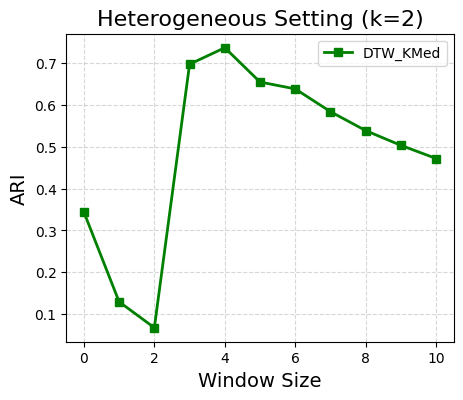

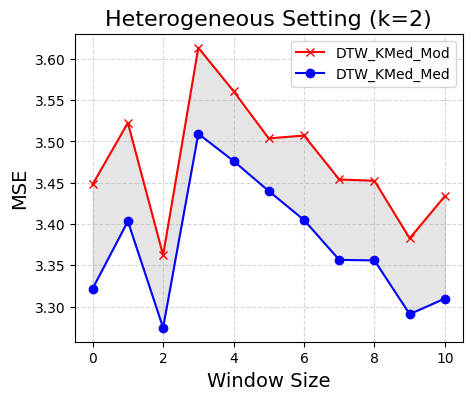

In [ ]:
with open("results_k2_window.pkl", "rb") as f:
    data = pickle.load(f)
    window_sizes = data["window_sizes"]
    ari_means_window = data["ari_means_window"]
    mse_mode_window = data["mse_mode_window"]
    mse_median_window = data["mse_median_window"]

# Gráfico ARI vs Window Size
plt.figure(figsize=(5, 4))
plt.plot(window_sizes, ari_means_window, label="DTW_KMed", marker='s', linestyle='-', linewidth=2, color="green")

plt.xlabel("Window Size", fontsize=14)
plt.ylabel("ARI", fontsize=14)
plt.title("Heterogeneous Setting (k=2)", fontsize=16)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Gráfico MSE vs Window Size (solo DTW_KMed)
plt.figure(figsize=(5, 4))
plt.plot(window_sizes, mse_mode_window, 'rx-', label="DTW_KMed_Mod")
plt.plot(window_sizes, mse_median_window, 'bo-', label="DTW_KMed_Med")
plt.fill_between(window_sizes, mse_mode_window, mse_median_window, color='gray', alpha=0.2)

plt.xlabel("Window Size", fontsize=14)
plt.ylabel("MSE", fontsize=14)
plt.title("Heterogeneous Setting (k=2)", fontsize=16)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
# Parámetros generales
T = 100
M = 5
n_series_total = 120
n_clusters = 3
sigma = 1
window_sizes = list(range(11))
n_simulations = 100

# Parámetros de sliding window
l = 21
s = 1

# Matriz de cargas y lags para k=3
B_k3 = np.zeros((n_series_total, 3))
L_k3 = np.zeros((n_series_total, 3), dtype=int)

# Asignación de series a factores y lags
for i in range(3):
    B_k3[i * 40:(i * 40 + 20), i] = 1  # Primer bloque de 20 series sin lag
    L_k3[i * 40:(i * 40 + 20), i] = 0

    B_k3[(i * 40 + 20):(i * 40 + 40), i] = 1  # Segundo bloque de 20 series con lag 3
    L_k3[(i * 40 + 20):(i * 40 + 40), i] = 3

# Inicializar estructuras para almacenar resultados
ari_means_window = []
mse_mode_window, mse_median_window = [], []

# Experimento variando window_size
for window_size in window_sizes:
    ari_scores = []
    mse_values_mode, mse_values_median = [], []

    for _ in range(n_simulations):
        # Generar los 3 factores f_t
        f_t = np.random.randn(T + M, 3)

        # Generar ruido
        noise = np.random.randn(T, n_series_total) * sigma

        # Construcción de las series temporales combinando factores según B_k3 y L_k3
        X_all = np.zeros((T, n_series_total))
        for serie_idx in range(n_series_total):
            lags = L_k3[serie_idx]
            f_t_selected = np.array([f_t[M + np.arange(T) - lags[f], f] for f in range(3)]).T
            X_all[:, serie_idx] = np.dot(f_t_selected, B_k3[serie_idx]) + noise[:, serie_idx]

        # Clustering con DTW_KMed
        kmed = KMedoids(dtw.distance_matrix, {"use_c": True, "parallel": True, "window": window_size}, k=n_clusters)
        kmed.fit(X_all.T)
        predicted_labels = np.zeros(n_series_total)
        for cluster_id, instances in enumerate(kmed.cluster_idx.keys()):
            for instance in kmed.cluster_idx[instances]:
                predicted_labels[instance] = cluster_id
        ari_scores.append(adjusted_rand_score(np.repeat([0, 1, 2], n_series_total // 3), predicted_labels))

        # Estimación de la matriz lead-lag usando moda y mediana
        lead_lag_mode = np.zeros((n_series_total, n_series_total))
        lead_lag_median = np.zeros((n_series_total, n_series_total))

        for i in range(n_series_total):
            for j in range(i, n_series_total):
                if predicted_labels[i] == predicted_labels[j]:
                    path = dtw.warping_path(X_all[:, i], X_all[:, j], use_c=True)
                    path_differences = np.array([t2 - t1 for t1, t2 in path])

                    if path_differences.size > 0:
                        lead_lag_mode[i, j] = mode(path_differences, keepdims=True).mode[0]
                        lead_lag_median[i, j] = np.median(path_differences)

                # Asegurar simetría en la matriz
                lead_lag_mode[j, i] = lead_lag_mode[i, j]
                lead_lag_median[j, i] = lead_lag_median[i, j]

        # Cálculo del error (MSE) solo para DTW_KMed
        error_matrix_mode, error_matrix_median = [], []

        for start in range(0, n_series_total - l + 1, s):
            window_estimate_mode = lead_lag_mode[start:start + l, start:start + l]
            window_estimate_median = lead_lag_median[start:start + l, start:start + l]
            true_lead_lag = np.abs(L_k3[start:start + l, None, :] - L_k3[None, start:start + l, :]).sum(axis=2)

            error_matrix_mode.append(np.nanmean((window_estimate_mode - true_lead_lag) ** 2))
            error_matrix_median.append(np.nanmean((window_estimate_median - true_lead_lag) ** 2))

        mse_values_mode.append(np.sqrt(np.nanmean(error_matrix_mode)))
        mse_values_median.append(np.sqrt(np.nanmean(error_matrix_median)))

    # Guardar resultados
    ari_means_window.append(np.mean(ari_scores))
    mse_mode_window.append(np.mean(mse_values_mode))
    mse_median_window.append(np.mean(mse_values_median))

with open("results_k3_window.pkl", "wb") as f:
    pickle.dump({
        "window_sizes": window_sizes,
        "ari_means_window": ari_means_window,
        "mse_mode_window": mse_mode_window,
        "mse_median_window": mse_median_window
    }, f)

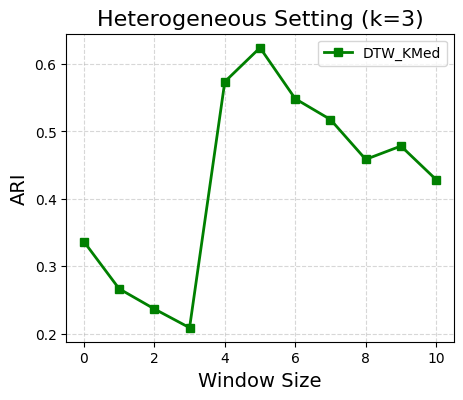

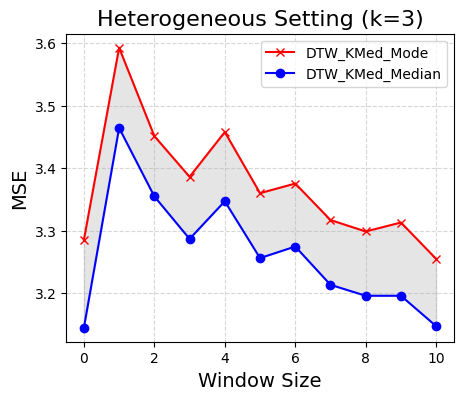

In [ ]:
with open("results_k3_window.pkl", "rb") as f:
    data = pickle.load(f)
    window_sizes = data["window_sizes"]
    ari_means_window = data["ari_means_window"]
    mse_mode_window = data["mse_mode_window"]
    mse_median_window = data["mse_median_window"]

# Gráfico ARI vs Window Size
plt.figure(figsize=(5, 4))
plt.plot(window_sizes, ari_means_window, label="DTW_KMed", marker='s', linestyle='-', linewidth=2, color="green")

plt.xlabel("Window Size", fontsize=14)
plt.ylabel("ARI", fontsize=14)
plt.title("Heterogeneous Setting (k=3)", fontsize=16)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Gráfico MSE vs Window Size (solo DTW_KMed)
plt.figure(figsize=(5, 4))
plt.plot(window_sizes, mse_mode_window, 'rx-', label="DTW_KMed_Mode")
plt.plot(window_sizes, mse_median_window, 'bo-', label="DTW_KMed_Median")
plt.fill_between(window_sizes, mse_mode_window, mse_median_window, color='gray', alpha=0.2)

plt.xlabel("Window Size", fontsize=14)
plt.ylabel("MSE", fontsize=14)
plt.title("Heterogeneous Setting (k=3)", fontsize=16)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 3. Real data: CRSP daily returns

`filtered_data.csv` is a long-format panel of daily returns for 500 U.S. equities identified by CRSP `PERMNO`, with the S&P 500 return (`sprtrn`) on the same day. The checks below confirm that every asset covers 2000-01-03 to 2019-12-31 and count missing returns per asset.

In [3]:
# Cargar los datos
filtered_data = pd.read_csv("filtered_data.csv", parse_dates=["date"])

In [4]:
# Obtener los PERMNOs únicos
top_500_permnos = filtered_data["PERMNO"].unique()

# Comprobar si cada PERMNO tiene las fechas inicial y final
missing_range_permnos = []

for permno in top_500_permnos:
    dates = filtered_data[filtered_data["PERMNO"] == permno]["date"]
    if pd.to_datetime("2000-01-03") not in dates.values or pd.to_datetime("2019-12-31") not in dates.values:
        missing_range_permnos.append(permno)

# Mostrar los PERMNOs que no tienen el rango completo de fechas
if missing_range_permnos:
    print(f"The following PERMNOs do not have data from 2000-01-03 to 2019-12-31:")
    print(missing_range_permnos)
else:
    print("All top 500 PERMNOs have full date range coverage.")

# Contar cuántos NaN hay en RET por PERMNO
nan_counts = filtered_data.groupby("PERMNO")["RET"].apply(lambda x: x.isna().sum())

# Mostrar resumen de NaNs
print("\n NaN count per PERMNO (Top 10 shown):")
print(nan_counts.sort_values(ascending=False).head(10))

[Output removed: it showed security-level CRSP data, which cannot be redistributed.]


In [5]:
# Elegir uno de los PERMNO del top 500 (por ejemplo, el primero)
sample_permno = top_500_permnos[0]

# Filtrar los datos de ese PERMNO
sample_df = filtered_data[filtered_data["PERMNO"] == sample_permno]

# Mostrar las primeras filas de ese PERMNO
print(f"Head of PERMNO {sample_permno}:")
print(sample_df.head())

[Output removed: it showed security-level CRSP data, which cannot be redistributed.]


## 4. Preprocessing

1. Pivot to a date × asset matrix of returns.
2. Drop days where more than 10% of assets have a zero return, and assets with more than 50% zero returns.
3. Excess return = `RET - sprtrn`.
4. Winsorize excess returns to [-15%, +15%].

The result is reshaped back to long format and turned into one winsorized excess-return series per asset.

In [6]:
print("\nStarting preprocessing...")

# Paso 1: Pivot de retornos
pivot_ret = filtered_data.pivot(index="date", columns="PERMNO", values="RET")
original_shape = pivot_ret.shape

# Paso 1.1: Eliminar días con más del 10% de retornos cero
threshold_zero_day = pivot_ret.shape[1] * 0.10
days_before = pivot_ret.shape[0]
pivot_ret = pivot_ret[pivot_ret.apply(lambda row: (row == 0).sum() <= threshold_zero_day, axis=1)]
days_after = pivot_ret.shape[0]
print(f"\nDays removed (more than 10% zeros): {days_before - days_after}")

# Paso 1.2: Eliminar activos con más del 50% de retornos cero
threshold_zero_asset = pivot_ret.shape[0] * 0.50
assets_before = pivot_ret.shape[1]
pivot_ret = pivot_ret.loc[:, (pivot_ret == 0).sum() <= threshold_zero_asset]
assets_after = pivot_ret.shape[1]
print(f"Assets removed (more than 50% zeros): {assets_before - assets_after}")

print(f"Remaining shape after filtering: {pivot_ret.shape}")

# Paso 2: Calcular exceso de retorno
pivot_sprtrn = filtered_data.pivot(index="date", columns="PERMNO", values="sprtrn")
pivot_sprtrn = pivot_sprtrn.reindex_like(pivot_ret)
excess_ret = pivot_ret - pivot_sprtrn

# Paso 3: Winsorización
winsorized_ret = excess_ret.clip(lower=-0.15, upper=0.15)


Starting preprocessing...

Days removed (more than 10% zeros): 270
Assets removed (more than 50% zeros): 0
Remaining shape after filtering: (4761, 500)


In [7]:
plt.figure(figsize=(14,5))
plt.plot(excess_ret[sample_permno], label="Before Winsorization", alpha=0.6)
plt.plot(winsorized_ret[sample_permno], label="After Winsorization", alpha=0.8)
plt.title(f"Excess Returns for PERMNO {sample_permno}")
plt.legend()
plt.grid(True)
plt.show()

print("\nSummary stats BEFORE winsorization:")
print(excess_ret.describe())

print("\nSummary stats AFTER winsorization:")
print(winsorized_ret.describe())

[Output removed: it showed security-level CRSP data, which cannot be redistributed.]


In [8]:
# Crear un DataFrame temporal con las nuevas columnas calculadas en formato largo
excess_df = excess_ret.reset_index().melt(id_vars="date", var_name="PERMNO", value_name="ExcessReturn")
winsor_df = winsorized_ret.reset_index().melt(id_vars="date", var_name="PERMNO", value_name="WinsorizedExcess")

# Asegurar que PERMNO es del mismo tipo (int)
excess_df["PERMNO"] = excess_df["PERMNO"].astype(int)
winsor_df["PERMNO"] = winsor_df["PERMNO"].astype(int)

# Unir las dos columnas nuevas
extras = pd.merge(excess_df, winsor_df, on=["date", "PERMNO"])

# Crear el DataFrame final preprocesado uniendo con los datos originales filtrados
preprocessed_data = pd.merge(
    filtered_data,
    extras,
    on=["date", "PERMNO"],
    how="inner"
)

# Ordenar por PERMNO y fecha
preprocessed_data = preprocessed_data.sort_values(by=["PERMNO", "date"])

# Mostrar ejemplo
print(preprocessed_data.head())

[Output removed: it showed security-level CRSP data, which cannot be redistributed.]


In [9]:
# Seleccionar el PERMNO que queremos comparar
permno_to_check = 15202

# Extraer datos antes del preprocesado
before_df = filtered_data[filtered_data["PERMNO"] == permno_to_check].sort_values("date")

# Extraer datos después del preprocesado
after_df = preprocessed_data[preprocessed_data["PERMNO"] == permno_to_check].sort_values("date")

# Mostrar las primeras filas de cada uno
print("BEFORE preprocessing (filtered_data):")
print(before_df.head())

print("\nAFTER preprocessing (preprocessed_data):")
print(after_df.head())

[Output removed: it showed security-level CRSP data, which cannot be redistributed.]


In [10]:
# Crear un diccionario para almacenar las series temporales de WinsorizedExcess
time_series_dict = {}

# Agrupar por PERMNO y extraer las series temporales
for permno, group in preprocessed_data.groupby("PERMNO"):
    # Usar la fecha como índice y ordenar
    ts = group[["date", "WinsorizedExcess"]].sort_values("date").set_index("date")["WinsorizedExcess"]
    time_series_dict[permno] = ts

print(f"Created {len(time_series_dict)} time series (one per PERMNO).")

# Mostrar algunas de ellas gráficamente
plt.figure(figsize=(14, 6))
for i, permno in enumerate(list(time_series_dict.keys())[:10]):
    plt.plot(time_series_dict[permno], label=f"PERMNO {permno}", alpha=0.7)

plt.title("Sample of Winsorized Excess Return Time Series")
plt.xlabel("Date")
plt.ylabel("Winsorized Excess Return")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

[Output removed: it showed security-level CRSP data, which cannot be redistributed.]


## 5. Lead-lag measures and trading framework

Shared parameters and functions used by every model:

- Rolling window of l = 21 days, step h = 1.
- **CCF baseline**: for each pair, the sum of absolute lagged cross-correlations (lags 1-5) in each direction gives a signed lead-lag score.
- **DTW_KMed**: K-Medoids with DTW distance (K = 5, window 5) on the window, then mode or median of the warping-path offsets for pairs in the same cluster.
- **Ranking**: the row sum of the lead-lag matrix Γ scores each asset; the top α = 25% are leaders, the rest laggards.
- **Signal**: exponentially weighted mean of the leaders' returns over the last p = 7 days.
- **Strategies**: Gβ trades the laggards on the leaders' signal; Dα trades the leaders on their own signal. PnL is the sign of the signal times the mean return δ = 7 days ahead.
- **Metrics**: PnL rescaled to 15% annualized volatility; Sharpe, Sortino, Calmar, max drawdown and hit rate.

In [11]:
# PARÁMETROS
alpha = 0.25
beta = 1 - alpha
p = 7
delta = 7
l = 21
h = 1
K = 5
window_size = 5

# FUNCIONES
def compute_ccf_matrix_fast(X_window, max_lag=5):
    n = X_window.shape[1]
    lead_lag_matrix = np.zeros((n, n))
    for i in range(n):
        xi = X_window[:, i]
        for j in range(n):
            xj = X_window[:, j]
            ccf_ij = [np.corrcoef(xi[lag:], xj[:-lag])[0, 1] for lag in range(1, max_lag + 1)]
            ccf_ji = [np.corrcoef(xj[lag:], xi[:-lag])[0, 1] for lag in range(1, max_lag + 1)]
            I_ij = np.nansum(np.abs(ccf_ij))
            I_ji = np.nansum(np.abs(ccf_ji))
            numerator = max(I_ij, I_ji) * np.sign(I_ij - I_ji)
            denominator = I_ij + I_ji if (I_ij + I_ji) != 0 else 1
            lead_lag_matrix[i, j] = numerator / denominator
    return lead_lag_matrix

def compute_dtw_kmed_diffs(data_window):
    n = len(data_window)
    kmed = KMedoids(dtw.distance_matrix, {"use_c": True, "parallel": True, "window": window_size}, k=K)
    kmed.fit(data_window)

    predicted_labels = np.zeros(n)
    for cluster_id, instances in enumerate(kmed.cluster_idx.keys()):
        for instance in kmed.cluster_idx[instances]:
            predicted_labels[instance] = cluster_id

    diffs_dict = {}
    for i in range(n):
        for j in range(i + 1, n):
            if predicted_labels[i] == predicted_labels[j]:
                path = dtw.warping_path(data_window[i], data_window[j], use_c=True)
                diffs = np.array([t2 - t1 for t1, t2 in path])
                diffs_dict[(i, j)] = diffs
    return diffs_dict, n

def build_lead_lag_matrix_from_diffs(diffs_dict, n, method="mode"):
    lead_lag_matrix = np.zeros((n, n))
    for (i, j), diffs in diffs_dict.items():
        if len(diffs) > 0:
            if method == "mode":
                m = mode(diffs, keepdims=False).mode
                val = m[0] if isinstance(m, np.ndarray) and m.size > 0 else m
            else:
                val = np.median(diffs)
            lead_lag_matrix[i, j] = val
            lead_lag_matrix[j, i] = -val
    return lead_lag_matrix

# NUEVA función: precomputar señales con DIFs, reutilizable para múltiples métodos
def precompute_diffs_signals(ts_df):
    ts_data = ts_df.values
    n, T = ts_data.shape[1], ts_data.shape[0]
    signals = []
    diffs_list = []

    for t in tqdm(range(l, T - delta, h), desc="Precomputing DTW diffs"):
        X_window_T = ts_data[t - l:t, :].T
        diffs_dict, n_series = compute_dtw_kmed_diffs(X_window_T)

        diffs_list.append((diffs_dict, n_series))

        # Calculamos la señal desde la info del clúster (sin usar method todavía)
        lead_lag_matrix_tmp = build_lead_lag_matrix_from_diffs(diffs_dict, n_series, method="mode")
        scores = lead_lag_matrix_tmp.sum(axis=1)
        ranking = np.argsort(-scores)
        top_n = int(n * alpha)
        leaders_idx = ranking[:top_n]
        laggers_idx = ranking[top_n:]

        past_ret = ts_data[t - p:t, leaders_idx].mean(axis=1)
        weights = np.exp(-np.linspace(p - 1, 0, p))
        weights /= weights.sum()
        signal = np.dot(weights, past_ret)

        signals.append((signal, leaders_idx, laggers_idx, t))

    return signals, diffs_list

# ANTIGUA función para modelos tipo CCF
def precompute_signals(ts_df, model_func):
    ts_data = ts_df.values
    n, T = ts_data.shape[1], ts_data.shape[0]
    signals = []

    for t in tqdm(range(l, T - delta, h), desc=f"Precomputing {model_func.__name__}"):
        X_window = ts_data[t - l:t, :]
        lead_lag_matrix = model_func(X_window)

        scores = lead_lag_matrix.sum(axis=1)
        ranking = np.argsort(-scores)
        top_n = int(n * alpha)
        leaders_idx = ranking[:top_n]
        laggers_idx = ranking[top_n:]

        past_ret = ts_data[t - p:t, leaders_idx].mean(axis=1)
        weights = np.exp(-np.linspace(p - 1, 0, p))
        weights /= weights.sum()
        signal = np.dot(weights, past_ret)

        signals.append((signal, leaders_idx, laggers_idx, t))

    return signals

# Aplica estrategia
def apply_strategy(ts_data, signals, strategy="Gβ"):
    pnl = []
    for signal, leaders_idx, laggers_idx, t in signals:
        if strategy == "Gβ":
            future_ret = ts_data[t + delta, laggers_idx].mean()
        else:
            future_ret = ts_data[t + delta, leaders_idx].mean()
        pnl.append(np.sign(signal) * future_ret)
    return np.array(pnl)

def compute_metrics_fast(pnl, name):
    pnl = np.asarray(pnl)
    daily_vol = np.std(pnl)
    pnl_rescaled = 0.15 / (daily_vol + 1e-8) * np.sqrt(252) * pnl
    cum_pnl = np.cumsum(pnl_rescaled)
    ann_ret = np.mean(pnl_rescaled) * 252
    vol = np.std(pnl_rescaled) * np.sqrt(252)
    downside_dev = np.sqrt(np.mean(np.minimum(pnl_rescaled, 0) ** 2)) * np.sqrt(252)
    mdd = np.max(np.maximum.accumulate(cum_pnl) - cum_pnl)
    sortino = ann_ret / (downside_dev + 1e-8)
    calmar = ann_ret / (mdd + 1e-8)
    hit_rate = (pnl_rescaled > 0).sum() / len(pnl_rescaled)
    sr = ann_ret / (vol + 1e-8)
    avg_pnl = np.mean(pnl_rescaled)

    return {
        "name": name,
        "pnl": pnl_rescaled,
        "cum_pnl": cum_pnl,
        "Sharpe Ratio": sr,
        "Sortino Ratio": sortino,
        "Calmar Ratio": calmar,
        "Max Drawdown": mdd,
        "Hit Rate": hit_rate,
        "PnL per trade": avg_pnl,
    }

# DATOS
dates = sorted(set().union(*[ts.index for ts in time_series_dict.values()]))
ts_df = pd.DataFrame({permno: ts.reindex(dates) for permno, ts in time_series_dict.items()}).dropna(axis=1)
data_np = ts_df.values.T
X = ts_df.values

## 6. Backtest: CCF vs DTW_KMed

Runs the rolling estimation over 4,733 windows for the CCF baseline and both DTW variants (mode and median). The CCF results from this first run are then dropped and CCF is recomputed with a corrected, parallel implementation before plotting the comparison.

In [ ]:
# MODELOS
models = {
    "CCF": "ccf",
    "DTW_KMed_Mod": "dtw_mode",
    "DTW_KMed_Med": "dtw_median",
}

# EJECUCIÓN DEL TRADING Y MÉTRICAS
results_gb, results_da = [], []

# 1. CCF (normal, guarda señales)
print("\nProcessing model: CCF")
signals_file = "CCF_signals.pkl"
if os.path.exists(signals_file):
    print(f"Loading existing signals from {signals_file}")
    with open(signals_file, "rb") as f:
        signals = pickle.load(f)
else:
    print("Computing signals for CCF")
    signals = precompute_signals(ts_df, compute_ccf_matrix_fast)
    with open(signals_file, "wb") as f:
        pickle.dump(signals, f)
    print(f"Saved signals to {signals_file}")

# Aplicar estrategias para CCF
pnl_gb = apply_strategy(ts_df.values, signals, strategy="Gβ")
pnl_da = apply_strategy(ts_df.values, signals, strategy="Dα")
metrics_gb = compute_metrics_fast(pnl_gb, "CCF_Gβ")
metrics_da = compute_metrics_fast(pnl_da, "CCF_Dα")
results_gb.append(metrics_gb)
results_da.append(metrics_da)

# 2. DTW-based modelos (sin guardar nada)
print("\nComputing DTW diffs and signals")
signals, diffs_list = precompute_diffs_signals(ts_df)

for method in ["mode", "median"]:
    model_name = "DTW_KMed_Mod" if method == "mode" else "DTW_KMed_Med"
    print(f"\nProcessing model: {model_name}")

    pnl_gb, pnl_da = [], []

    for (diffs_dict, n), (signal, _, _, t) in zip(diffs_list, signals):
        lead_lag_matrix = build_lead_lag_matrix_from_diffs(diffs_dict, n, method=method)
        scores = lead_lag_matrix.sum(axis=1)
        ranking = np.argsort(-scores)
        top_n = int(X.shape[1] * alpha)
        leaders_idx = ranking[:top_n]
        laggers_idx = ranking[top_n:]

        future_ret_gb = X[t + delta, laggers_idx].mean()
        future_ret_da = X[t + delta, leaders_idx].mean()
        signed_signal = np.sign(signal)

        pnl_gb.append(signed_signal * future_ret_gb)
        pnl_da.append(signed_signal * future_ret_da)

    metrics_gb = compute_metrics_fast(pnl_gb, f"{model_name}_Gβ")
    metrics_da = compute_metrics_fast(pnl_da, f"{model_name}_Dα")
    results_gb.append(metrics_gb)
    results_da.append(metrics_da)

# Guardar todos los resultados juntos
with open("trading_results.pkl", "wb") as f:
    pickle.dump((results_gb, results_da), f)


Processing model: CCF
Loading existing signals from CCF_signals.pkl

Computing DTW diffs and signals


Precomputing DTW diffs: 100%|██████████| 4733/4733 [9:54:53<00:00,  7.54s/it]  



Processing model: DTW_KMed_Mod

Processing model: DTW_KMed_Med


In [ ]:
# Cargar el archivo original
with open("trading_results.pkl", "rb") as f:
    results_gb, results_da = pickle.load(f)

# Filtrar resultados para eliminar CCF
results_gb_cleaned = [r for r in results_gb if not r["name"].startswith("CCF")]
results_da_cleaned = [r for r in results_da if not r["name"].startswith("CCF")]

# Guardar archivo limpio
with open("trading_results_no_ccf.pkl", "wb") as f:
    pickle.dump((results_gb_cleaned, results_da_cleaned), f)

print("Resultados sin CCF guardados en 'trading_results_no_ccf.pkl'")

Resultados sin CCF guardados en 'trading_results_no_ccf.pkl'


In [ ]:
def compute_ccf_matrix_parallel(X_window, max_lag=5, n_jobs=-1):
    n = X_window.shape[1]
    lead_lag_matrix = np.zeros((n, n))

    results = Parallel(n_jobs=n_jobs)(
        delayed(ccf_between_pairs)(i, X_window, n, max_lag) for i in range(n)
    )

    for i, row in results:
        lead_lag_matrix[i, :] = row
        for j in range(i + 1, n):
            lead_lag_matrix[j, i] = -row[j]

    return lead_lag_matrix

def ccf_between_pairs(i, X_window, n, max_lag=5):
    xi = X_window[:, i] - X_window[:, i].mean()
    row = np.zeros(n)

    for j in range(i + 1, n):
        xj = X_window[:, j] - X_window[:, j].mean()

        ccf_ij, ccf_ji = [], []

        for lag in range(1, max_lag + 1):
            xi_lag = xi[lag:]
            xj_lag = xj[:-lag]
            xj_lag_rev = xj[lag:]
            xi_lag_rev = xi[:-lag]

            corr_ij = np.dot(xi_lag, xj_lag) / (np.std(xi_lag) * np.std(xj_lag) * len(xi_lag)) if np.std(xi_lag) > 0 and np.std(xj_lag) > 0 else 0.0
            corr_ji = np.dot(xj_lag_rev, xi_lag_rev) / (np.std(xj_lag_rev) * np.std(xi_lag_rev) * len(xj_lag_rev)) if np.std(xj_lag_rev) > 0 and np.std(xi_lag_rev) > 0 else 0.0

            ccf_ij.append(abs(corr_ij))
            ccf_ji.append(abs(corr_ji))

        I_ij = np.sum(ccf_ij)
        I_ji = np.sum(ccf_ji)
        numerator = max(I_ij, I_ji) * np.sign(I_ij - I_ji)
        denominator = I_ij + I_ji if (I_ij + I_ji) != 0 else 1
        gamma = numerator / denominator

        row[j] = gamma

    return i, row

def precompute_signals_with_progress_parallel(ts_df, model_func, max_lag=5):
    ts_data = ts_df.values
    n, T = ts_data.shape[1], ts_data.shape[0]
    signals = []

    weights = np.exp(-np.linspace(p - 1, 0, p))
    weights /= weights.sum()

    for t in tqdm(range(l, T - delta, h), desc="Computing CCF signals (Parallel)"):
        X_window = ts_data[t - l:t, :]
        lead_lag_matrix = model_func(X_window, max_lag=max_lag)

        scores = lead_lag_matrix.sum(axis=1)
        ranking = np.argsort(-scores)
        top_n = int(n * alpha)
        leaders_idx = ranking[:top_n]
        laggers_idx = ranking[top_n:]

        past_ret = ts_data[t - p:t, leaders_idx].mean(axis=1)
        signal = np.dot(weights, past_ret)

        signals.append((signal, leaders_idx, laggers_idx, t))

    return signals

In [ ]:
# Recalcular señales de CCF (versión paralela optimizada con barra de progreso)
signals_ccf = precompute_signals_with_progress_parallel(ts_df, compute_ccf_matrix_parallel, max_lag=5)

# Calcular métricas
pnl_gb = apply_strategy(ts_df.values, signals_ccf, strategy="Gβ")
pnl_da = apply_strategy(ts_df.values, signals_ccf, strategy="Dα")
metrics_gb = compute_metrics_fast(pnl_gb, "CCF_Gβ")
metrics_da = compute_metrics_fast(pnl_da, "CCF_Dα")

# Cargar archivo original sin CCF
with open("trading_results_no_ccf.pkl", "rb") as f:
    results_gb, results_da = pickle.load(f)

# Añadir resultados CCF
results_gb.append(metrics_gb)
results_da.append(metrics_da)

# Guardar en archivo final completo
with open("trading_results.pkl", "wb") as f:
    pickle.dump((results_gb, results_da), f)

print("CCF corregido añadido a 'trading_results.pkl'")

Computing CCF signals (Parallel): 100%|██████████| 4733/4733 [20:48:31<00:00, 15.83s/it]   


CCF corregido añadido a 'trading_results.pkl'


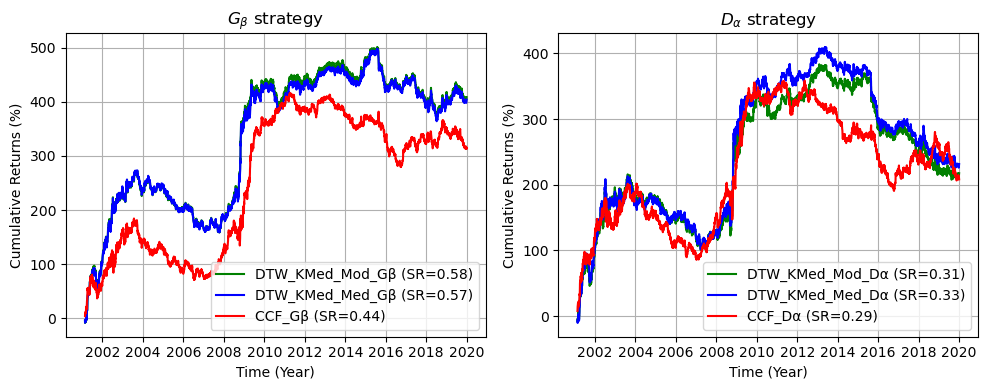


Gβ Strategy Metrics
                 Sharpe Ratio  Sortino Ratio  Calmar Ratio  Hit Rate
name                                                                
DTW_KMed_Mod_Gβ         0.576          0.864         0.164     0.509
DTW_KMed_Med_Gβ         0.569          0.852         0.160     0.510
CCF_Gβ                  0.442          0.655         0.122     0.512

Dα Strategy Metrics
                 Sharpe Ratio  Sortino Ratio  Calmar Ratio  Hit Rate
name                                                                
DTW_KMed_Mod_Dα         0.306          0.454         0.066     0.500
DTW_KMed_Med_Dα         0.326          0.483         0.067     0.506
CCF_Dα                  0.293          0.428         0.066     0.507


In [ ]:
# Cargar resultados guardados
with open("trading_results.pkl", "rb") as f:
    results_gb, results_da = pickle.load(f)

colors = {
    "CCF": "red",
    "DTW_KMed_Mod": "green",
    "DTW_KMed_Med": "blue",
}

plt.figure(figsize=(10, 4))

# Gβ
plt.subplot(1, 2, 1)
for res in results_gb:
    base_name = res["name"].replace("_Gβ", "")
    plt.plot(ts_df.index[l+delta:], res["cum_pnl"],
             label=f"{res['name']} (SR={res['Sharpe Ratio']:.2f})",
             color=colors[base_name])
plt.title(r"$G_{\beta}$ strategy")
plt.xlabel("Time (Year)")
plt.ylabel("Cumulative Returns (%)")
plt.legend()
plt.grid(True)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))

# Dα
plt.subplot(1, 2, 2)
for res in results_da:
    base_name = res["name"].replace("_Dα", "")
    plt.plot(ts_df.index[l+delta:], res["cum_pnl"],
             label=f"{res['name']} (SR={res['Sharpe Ratio']:.2f})",
             color=colors[base_name])
plt.title(r"$D_{\alpha}$ strategy")
plt.xlabel("Time (Year)")
plt.ylabel("Cumulative Returns (%)")
plt.legend()
plt.grid(True)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))

plt.tight_layout()
plt.show()

def print_metrics_table(results, title):
    print(f"\n{title}")
    df = pd.DataFrame([{
        k: round(v, 3) if isinstance(v, float) else v
        for k, v in r.items()
        if k in ["name", "Sharpe Ratio", "Sortino Ratio", "Calmar Ratio", "Hit Rate"]
    } for r in results])
    df.set_index("name", inplace=True)
    print(df)

print_metrics_table(results_gb, "Gβ Strategy Metrics")
print_metrics_table(results_da, "Dα Strategy Metrics")

## 7. Multireference alignment: illustration

Toy example of homogeneous MRA: 500 noisy, cyclically shifted copies of one latent signal. Estimating each shift by correlation and averaging the realigned copies gives an estimate that tracks the true signal at σ = 0.5 and at σ = 2, even though individual copies are heavily distorted at σ = 2.

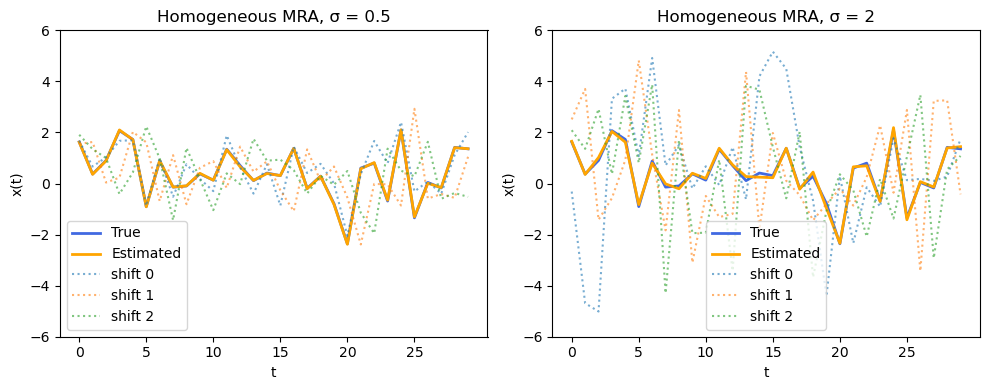

In [12]:
# CONFIGURACIÓN GENERAL
T = 30
N = 500
max_shift = 2
np.random.seed(0)

# SEÑAL VERDADERA
x_true = np.random.randn(T)
x_true = x_true / np.std(x_true)

plt.figure(figsize=(10, 4))

for i, sigma in enumerate([0.5, 2]):
    shifts = np.random.randint(0, max_shift + 1, size=N)
    Y = np.zeros((N, T))

    for j in range(N):
        shifted = np.roll(x_true, shifts[j])
        noise = np.random.randn(T) * sigma
        Y[j] = shifted + noise

    estimated_shifts = []
    for y in Y:
        correlations = [np.correlate(y, np.roll(x_true, r)) for r in range(max_shift + 1)]
        best_r = np.argmax(correlations)
        estimated_shifts.append(best_r)

    aligned_Y = np.array([np.roll(y, -r) for y, r in zip(Y, estimated_shifts)])
    x_estimated = aligned_Y.mean(axis=0)

    plt.subplot(1, 2, i+1)
    plt.plot(x_true, label="True", linewidth=2, color="royalblue")
    plt.plot(x_estimated, label="Estimated", linewidth=2, color="orange")

    for r in range(3):
        idx = np.where(shifts == r)[0][0]
        plt.plot(Y[idx], linestyle=":", label=f"shift {r}", alpha=0.6)

    plt.title(f"Homogeneous MRA, σ = {sigma}")
    plt.xlabel("t")
    plt.ylabel("x(t)")
    plt.ylim(-6, 6)
    plt.xticks(np.arange(0, T, 5))
    plt.legend()

plt.tight_layout()
plt.show()

## 8. Synthetic benchmark: MRA clustering (SPC vs IVF)

K ∈ {2, 3, 4} latent signals of length T = 50; 500 series are drawn with Dirichlet class proportions, random cyclic shifts up to 2 and Gaussian noise σ ∈ {0, 0.5, ..., 3}; 100 repetitions per setting.

Compared clustering methods (ARI against true classes):

- **SPC**: spectral clustering on the matrix of maximum shifted correlations.
- **IVF**: each series is assigned to the estimated latent signal with the highest shifted correlation (IVF + 1-NN).

In [4]:
# ---------------- CONFIGURACIÓN ----------------
N = 500
T = 50
smax = 2
delta = 5
sigmas = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
K = 2
repeats = 100

# ---------------- FUNCIONES ----------------
def generate_synthetic_data(T, N, K, smax, sigma):
    base_signals = [np.random.randn(T) for _ in range(K)]
    base_signals = [x / np.std(x) for x in base_signals]

    proportions = np.random.dirichlet(np.ones(K))
    Nk = (proportions * N).astype(int)
    Nk[-1] = N - np.sum(Nk[:-1])

    Y, true_labels = [], []
    for k in range(K):
        for _ in range(Nk[k]):
            shift = np.random.randint(0, smax + 1)
            signal = np.roll(base_signals[k], shift)
            if shift > 0:
                signal[:shift] = np.random.randn(shift)
            noise = np.random.randn(T) * sigma
            Y.append(signal + noise)
            true_labels.append(k)

    Y = np.array(Y)
    true_labels = np.array(true_labels)

    # Estimación de señales
    estimated_signals = [Y[true_labels == k].mean(axis=0) for k in range(K)]
    estimated_signals = [x / (np.std(x) + 1e-8) for x in estimated_signals]

    return Y, true_labels, estimated_signals

def compute_similarity_matrix_parallel(Y, delta):
    Y = (Y - Y.mean(axis=1, keepdims=True)) / (Y.std(axis=1, keepdims=True) + 1e-8)

    def max_corr(i, j):
        return (i, j, max([
            np.corrcoef(np.roll(Y[i], lag), Y[j])[0, 1]
            for lag in range(-delta, delta + 1)
        ]))

    N = len(Y)
    S = np.zeros((N, N))
    results = Parallel(n_jobs=-1)(
        delayed(max_corr)(i, j) for i in range(N) for j in range(i + 1, N)
    )
    for i, j, val in results:
        S[i, j] = S[j, i] = val
    return S

def assign_by_shifted_correlation(Y, signals):
    N, T = Y.shape
    K = len(signals)
    corrs = np.zeros((N, K))

    Y_norm = (Y - Y.mean(axis=1, keepdims=True)) / (Y.std(axis=1, keepdims=True) + 1e-8)
    for k, x in enumerate(signals):
        x = (x - np.mean(x)) / (np.std(x) + 1e-8)
        for lag in range(T):
            x_shift = np.roll(x, lag)
            score = (Y_norm @ x_shift) / T
            corrs[:, k] = np.maximum(corrs[:, k], score)

    return np.argmax(corrs, axis=1)

# ---------------- EXPERIMENTO PRINCIPAL ----------------
ari_spc, ari_ivf = [], []

for sigma in tqdm(sigmas, desc="Running ARI Comparison (K=2)"):
    ari_spc_sigma, ari_ivf_sigma = [], []

    for _ in range(repeats):
        Y, true_labels, estimated_signals = generate_synthetic_data(T, N, K, smax, sigma)

        # SPC
        S = compute_similarity_matrix_parallel(Y, delta)
        spc = SpectralClustering(n_clusters=K, affinity='precomputed', assign_labels='kmeans')
        spc_labels = spc.fit_predict(S)

        # IVF-1NN
        ivf_labels = assign_by_shifted_correlation(Y, estimated_signals)

        # ARI
        ari_spc_sigma.append(adjusted_rand_score(true_labels, spc_labels))
        ari_ivf_sigma.append(adjusted_rand_score(true_labels, ivf_labels))

    ari_spc.append(np.mean(ari_spc_sigma))
    ari_ivf.append(np.mean(ari_ivf_sigma))

# ---------------- GUARDAR ----------------
with open("results_k2_ivf_spc.pkl", "wb") as f:
    pickle.dump({"sigma": sigmas, "IVF": ari_ivf, "SPC": ari_spc}, f)

Running ARI Comparison (K=2): 100%|██████████| 7/7 [3:29:19<00:00, 1794.22s/it]  


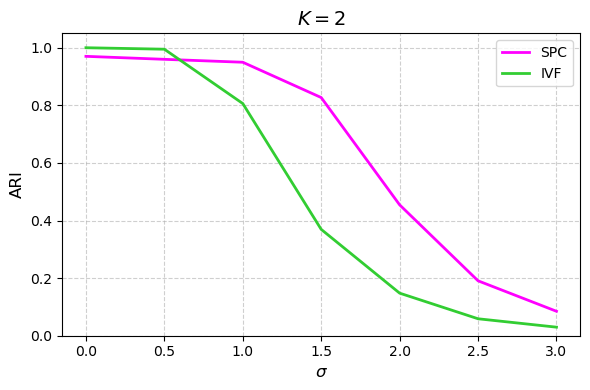

In [5]:
# Cargar los resultados
with open("results_k2_ivf_spc.pkl", "rb") as f:  
    results = pickle.load(f)

# Plot
plt.figure(figsize=(6, 4))
plt.plot(results['sigma'], results['SPC'], label="SPC", color="magenta", linewidth=2)
plt.plot(results['sigma'], results['IVF'], label="IVF", color="limegreen", linewidth=2)
plt.xlabel(r"$\sigma$", fontsize=12)
plt.ylabel("ARI", fontsize=12)
plt.title(r"$K=2$", fontsize=14)
plt.ylim(0, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
# ---------------- CONFIGURACIÓN ----------------
N = 500
T = 50
smax = 2
delta = 5
sigmas = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
K = 3
repeats = 100

# ---------------- FUNCIONES ----------------
def generate_synthetic_data(T, N, K, smax, sigma):
    base_signals = [np.random.randn(T) for _ in range(K)]
    base_signals = [x / np.std(x) for x in base_signals]

    proportions = np.random.dirichlet(np.ones(K))
    Nk = (proportions * N).astype(int)
    Nk[-1] = N - np.sum(Nk[:-1])

    Y, true_labels = [], []
    for k in range(K):
        for _ in range(Nk[k]):
            shift = np.random.randint(0, smax + 1)
            signal = np.roll(base_signals[k], shift)
            if shift > 0:
                signal[:shift] = np.random.randn(shift)
            noise = np.random.randn(T) * sigma
            Y.append(signal + noise)
            true_labels.append(k)

    Y = np.array(Y)
    true_labels = np.array(true_labels)

    estimated_signals = [Y[true_labels == k].mean(axis=0) for k in range(K)]
    estimated_signals = [x / (np.std(x) + 1e-8) for x in estimated_signals]

    return Y, true_labels, estimated_signals

def compute_similarity_matrix_parallel(Y, delta):
    Y = (Y - Y.mean(axis=1, keepdims=True)) / (Y.std(axis=1, keepdims=True) + 1e-8)

    def max_corr(i, j):
        return (i, j, max([
            np.corrcoef(np.roll(Y[i], lag), Y[j])[0, 1]
            for lag in range(-delta, delta + 1)
        ]))

    N = len(Y)
    S = np.zeros((N, N))
    results = Parallel(n_jobs=-1)(
        delayed(max_corr)(i, j) for i in range(N) for j in range(i + 1, N)
    )
    for i, j, val in results:
        S[i, j] = S[j, i] = val
    return S

def assign_by_shifted_correlation(Y, signals):
    N, T = Y.shape
    K = len(signals)
    corrs = np.zeros((N, K))

    Y_norm = (Y - Y.mean(axis=1, keepdims=True)) / (Y.std(axis=1, keepdims=True) + 1e-8)
    for k, x in enumerate(signals):
        x = (x - np.mean(x)) / (np.std(x) + 1e-8)
        for lag in range(T):
            x_shift = np.roll(x, lag)
            score = (Y_norm @ x_shift) / T
            corrs[:, k] = np.maximum(corrs[:, k], score)

    return np.argmax(corrs, axis=1)

# ---------------- EXPERIMENTO PRINCIPAL ----------------
ari_spc, ari_ivf = [], []

for sigma in tqdm(sigmas, desc="Running ARI Comparison (K=3)"):
    ari_spc_sigma, ari_ivf_sigma = [], []

    for _ in range(repeats):
        Y, true_labels, estimated_signals = generate_synthetic_data(T, N, K, smax, sigma)

        # SPC
        S = compute_similarity_matrix_parallel(Y, delta)
        spc = SpectralClustering(n_clusters=K, affinity='precomputed', assign_labels='kmeans')
        spc_labels = spc.fit_predict(S)

        # IVF-1NN
        ivf_labels = assign_by_shifted_correlation(Y, estimated_signals)

        # ARI
        ari_spc_sigma.append(adjusted_rand_score(true_labels, spc_labels))
        ari_ivf_sigma.append(adjusted_rand_score(true_labels, ivf_labels))

    ari_spc.append(np.mean(ari_spc_sigma))
    ari_ivf.append(np.mean(ari_ivf_sigma))

# ---------------- GUARDAR ----------------
with open("results_k3_ivf_spc.pkl", "wb") as f:
    pickle.dump({"sigma": sigmas, "IVF": ari_ivf, "SPC": ari_spc}, f)

Running ARI Comparison (K=3): 100%|██████████| 7/7 [3:29:12<00:00, 1793.27s/it]  


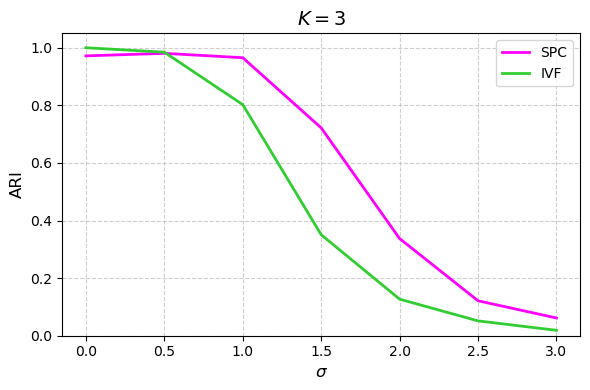

In [7]:
# Cargar los resultados
with open("results_k3_ivf_spc.pkl", "rb") as f:
    results = pickle.load(f)

# Plot
plt.figure(figsize=(6, 4))
plt.plot(results['sigma'], results['SPC'], label="SPC", color="magenta", linewidth=2)
plt.plot(results['sigma'], results['IVF'], label="IVF", color="limegreen", linewidth=2)
plt.xlabel(r"$\sigma$", fontsize=12)
plt.ylabel("ARI", fontsize=12)
plt.title(r"$K=3$", fontsize=14)
plt.ylim(0, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
# ---------------- CONFIGURACIÓN ----------------
N = 500
T = 50
smax = 2
delta = 5
sigmas = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
K = 4
repeats = 100

# ---------------- FUNCIONES ----------------
def generate_synthetic_data(T, N, K, smax, sigma):
    base_signals = [np.random.randn(T) for _ in range(K)]
    base_signals = [x / np.std(x) for x in base_signals]

    proportions = np.random.dirichlet(np.ones(K))
    Nk = (proportions * N).astype(int)
    Nk[-1] = N - np.sum(Nk[:-1])

    Y, true_labels = [], []
    for k in range(K):
        for _ in range(Nk[k]):
            shift = np.random.randint(0, smax + 1)
            signal = np.roll(base_signals[k], shift)
            if shift > 0:
                signal[:shift] = np.random.randn(shift)
            noise = np.random.randn(T) * sigma
            Y.append(signal + noise)
            true_labels.append(k)

    Y = np.array(Y)
    true_labels = np.array(true_labels)

    estimated_signals = [Y[true_labels == k].mean(axis=0) for k in range(K)]
    estimated_signals = [x / (np.std(x) + 1e-8) for x in estimated_signals]

    return Y, true_labels, estimated_signals

def compute_similarity_matrix_parallel(Y, delta):
    Y = (Y - Y.mean(axis=1, keepdims=True)) / (Y.std(axis=1, keepdims=True) + 1e-8)

    def max_corr(i, j):
        return (i, j, max([
            np.corrcoef(np.roll(Y[i], lag), Y[j])[0, 1]
            for lag in range(-delta, delta + 1)
        ]))

    N = len(Y)
    S = np.zeros((N, N))
    results = Parallel(n_jobs=-1)(
        delayed(max_corr)(i, j) for i in range(N) for j in range(i + 1, N)
    )
    for i, j, val in results:
        S[i, j] = S[j, i] = val
    return S

def assign_by_shifted_correlation(Y, signals):
    N, T = Y.shape
    K = len(signals)
    corrs = np.zeros((N, K))

    Y_norm = (Y - Y.mean(axis=1, keepdims=True)) / (Y.std(axis=1, keepdims=True) + 1e-8)
    for k, x in enumerate(signals):
        x = (x - np.mean(x)) / (np.std(x) + 1e-8)
        for lag in range(T):
            x_shift = np.roll(x, lag)
            score = (Y_norm @ x_shift) / T
            corrs[:, k] = np.maximum(corrs[:, k], score)

    return np.argmax(corrs, axis=1)

# ---------------- EXPERIMENTO PRINCIPAL ----------------
ari_spc, ari_ivf = [], []

for sigma in tqdm(sigmas, desc="Running ARI Comparison (K=4)"):
    ari_spc_sigma, ari_ivf_sigma = [], []

    for _ in range(repeats):
        Y, true_labels, estimated_signals = generate_synthetic_data(T, N, K, smax, sigma)

        # SPC
        S = compute_similarity_matrix_parallel(Y, delta)
        spc = SpectralClustering(n_clusters=K, affinity='precomputed', assign_labels='kmeans')
        spc_labels = spc.fit_predict(S)

        # IVF-1NN
        ivf_labels = assign_by_shifted_correlation(Y, estimated_signals)

        # ARI
        ari_spc_sigma.append(adjusted_rand_score(true_labels, spc_labels))
        ari_ivf_sigma.append(adjusted_rand_score(true_labels, ivf_labels))

    ari_spc.append(np.mean(ari_spc_sigma))
    ari_ivf.append(np.mean(ari_ivf_sigma))

# ---------------- GUARDAR ----------------
with open("results_k4_ivf_spc.pkl", "wb") as f:
    pickle.dump({"sigma": sigmas, "IVF": ari_ivf, "SPC": ari_spc}, f)

Running ARI Comparison (K=4): 100%|██████████| 7/7 [3:34:34<00:00, 1839.26s/it]  


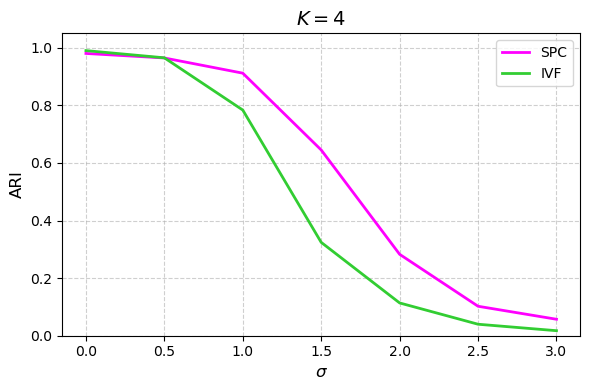

In [5]:
# Cargar los resultados
with open("results_k4_ivf_spc.pkl", "rb") as f:
    results = pickle.load(f)

# Plot
plt.figure(figsize=(6, 4))
plt.plot(results['sigma'], results['SPC'], label="SPC", color="magenta", linewidth=2)
plt.plot(results['sigma'], results['IVF'], label="IVF", color="limegreen", linewidth=2)
plt.xlabel(r"$\sigma$", fontsize=12)
plt.ylabel("ARI", fontsize=12)
plt.title(r"$K=4$", fontsize=14)
plt.ylim(0, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## 9. MRA-based trading strategies

Four MRA variants are plugged into the same trading framework (K = 5 clusters, lags up to 7, α = 0.25, p = 7, l = 21):

- **S-Pairwise**: spectral clustering, then row sums of the pairwise best-lag matrix within each cluster.
- **S-Sync**: spectral clustering, then SVD synchronization of the lag matrix to get one lag per asset.
- **S-IVFhomo**: spectral clustering, then a homogeneous reference signal per cluster and each asset's lag to it.
- **I-IVFhet**: assignment to K random reference series by best shifted correlation, ranked by the resulting lag.

The first S-Pairwise and S-Sync implementations here are discarded in the next section.

In [123]:
# ------------------ DATOS ------------------
with open("trading_results.pkl", "rb") as f:
    results_gb, results_da = pickle.load(f)

X = ts_df.values
n, T = X.shape[1], X.shape[0]
weights = np.exp(-np.linspace(p - 1, 0, p))
weights /= weights.sum()

In [124]:
# ------------------ S-PAIRWISE ------------------
print("Processing S-PAIRWISE...")

# Eliminar resultados previos del modelo S-Pairwise (si existen)
results_gb = [res for res in results_gb if not res["name"].startswith("S-Pairwise")]
results_da = [res for res in results_da if not res["name"].startswith("S-Pairwise")]

def compute_spairwise_matrix_and_lags_vectorized(X_window, delta):
    """
    Calcula las matrices S_δ y L_δ de forma completamente vectorizada.
    S cumple: S[i, j] = max_lag Corr(X_i, X_j)[lag]
    L cumple: L[i, j] = lag en que se logra la máxima correlación, L.T = -L
    """
    T, n = X_window.shape
    Xc = X_window - X_window.mean(axis=0)
    Xc = Xc / (Xc.std(axis=0) + 1e-8)  # Normalización columna a columna

    lags = np.arange(-delta, delta + 1)
    X_shifted = np.zeros((len(lags), T, n))

    for idx, lag in enumerate(lags):
        if lag < 0:
            X_shifted[idx, :lag, :] = Xc[-lag:, :]
        elif lag > 0:
            X_shifted[idx, lag:, :] = Xc[:-lag, :]
        else:
            X_shifted[idx, :, :] = Xc

    # Producto interno entre Xc y versiones desplazadas
    # Resultado: (lags, n, n)
    correlations = np.einsum('ltn,tm->lnm', X_shifted, Xc) / T

    # Máxima correlación y lag asociado
    best_corrs = np.max(correlations, axis=0)
    best_lags_idx = np.argmax(correlations, axis=0)
    best_lags = lags[best_lags_idx]

    S = best_corrs
    L = best_lags - best_lags.T  # Skew-symmetric como en el paper

    return S, L


def precompute_signals_spairwise(ts_df, K, delta, alpha, p, l, h):
    ts_data = ts_df.values
    n, T = ts_data.shape[1], ts_data.shape[0]
    signals = []

    weights = np.exp(-np.linspace(p - 1, 0, p))
    weights /= weights.sum()

    for t in tqdm(range(l, T - delta, h), desc="S-Pairwise (Vectorized)"):
        X_window = ts_data[t - l:t, :]
        try:
            S, L = compute_spairwise_matrix_and_lags_vectorized(X_window, delta)
            labels = SpectralClustering(n_clusters=K, affinity='precomputed', assign_labels='kmeans', random_state=42).fit_predict(S)
        except Exception as e:
            print(f"Skipping window t={t} due to error: {e}")
            continue

        scores = np.zeros(n)
        for k_ in range(K):
            idx = np.where(labels == k_)[0]
            if len(idx) < 2:
                continue
            scores[idx] = L[np.ix_(idx, idx)].sum(axis=1)

        ranking = np.argsort(-scores)
        top_n = int(n * alpha)
        leaders_idx = ranking[:top_n]
        laggers_idx = ranking[top_n:]

        past_ret = ts_data[t - p:t, leaders_idx].mean(axis=1)
        signal = np.dot(weights, past_ret)

        signals.append((signal, leaders_idx, laggers_idx, t))

    return signals

# Generar señales vectorizadas de S-Pairwise
signals_spairwise = precompute_signals_spairwise(ts_df, K=5, delta=7, alpha=0.25, p=7, l=21, h=1)

# Aplicar estrategias de trading
pnl_gb = apply_strategy(ts_df.values, signals_spairwise, strategy="Gβ")
pnl_da = apply_strategy(ts_df.values, signals_spairwise, strategy="Dα")

metrics_gb = compute_metrics_fast(pnl_gb, "S-Pairwise_Gβ")
metrics_da = compute_metrics_fast(pnl_da, "S-Pairwise_Dα")

# Guardar métricas en las listas de resultados
results_gb.append(metrics_gb)
results_da.append(metrics_da)

Processing S-PAIRWISE...


S-Pairwise (Vectorized): 100%|██████████| 4733/4733 [1:11:19<00:00,  1.11it/s]  


In [125]:
# ------------------ S-SYNC ------------------
print("Processing S-SYNC...")

# Eliminar resultados previos del modelo S-Pairwise (si existen)
results_gb = [res for res in results_gb if not res["name"].startswith("S-Sync")]
results_da = [res for res in results_da if not res["name"].startswith("S-Sync")]

def compute_spairwise_matrix_and_lags_vectorized(X_window, delta):
    T, n = X_window.shape
    Xc = X_window - X_window.mean(axis=0)
    Xc = Xc / (Xc.std(axis=0) + 1e-8)

    lags = np.arange(-delta, delta + 1)
    X_shifted = np.zeros((len(lags), T, n))

    for idx, lag in enumerate(lags):
        if lag < 0:
            X_shifted[idx, :lag, :] = Xc[-lag:, :]
        elif lag > 0:
            X_shifted[idx, lag:, :] = Xc[:-lag, :]
        else:
            X_shifted[idx, :, :] = Xc

    correlations = np.einsum('ltn,tm->lnm', X_shifted, Xc) / T
    best_corrs = np.max(correlations, axis=0)
    best_lags_idx = np.argmax(correlations, axis=0)
    best_lags = lags[best_lags_idx]

    S = best_corrs
    L = best_lags - best_lags.T  # skew-symmetric

    return S, L

def svd_sync(L_block):
    """
    SVD-NRS algorithm from Sec. 3.1 to recover relative lag vector r_hat.
    L_block must be skew-symmetric.
    """
    U, s, Vt = np.linalg.svd(L_block)
    r_hat = U[:, 0] - U[:, 1]  # take linear combination of top 2 singular vectors
    r_hat -= np.min(r_hat)    # shift to be non-negative
    return r_hat

def precompute_signals_ssync(ts_df, K, delta, alpha, p, l, h):
    ts_data = ts_df.values
    n, T = ts_data.shape[1], ts_data.shape[0]
    signals = []

    weights = np.exp(-np.linspace(p - 1, 0, p))
    weights /= weights.sum()

    for t in tqdm(range(l, T - delta, h), desc="S-Sync (SVD-NRS)"):
        X_window = ts_data[t - l:t, :]
        try:
            S, L = compute_spairwise_matrix_and_lags_vectorized(X_window, delta)
            labels = SpectralClustering(n_clusters=K, affinity='precomputed', assign_labels='kmeans', random_state=42).fit_predict(S)
        except Exception as e:
            print(f"Skipping window t={t} due to error: {e}")
            continue

        # Estimar lags relativos con SVD-NRS por grupo
        r_global = np.full(n, np.nan)
        for k_ in range(K):
            idx = np.where(labels == k_)[0]
            if len(idx) < 2:
                continue
            L_block = L[np.ix_(idx, idx)]
            r_hat = svd_sync(L_block)
            r_global[idx] = r_hat

        # Rankear según menor r (más líder)
        valid = ~np.isnan(r_global)
        if np.sum(valid) < 2:
            continue
        ranking = np.argsort(r_global[valid])
        idx_valid = np.where(valid)[0]
        sorted_indices = idx_valid[ranking]

        top_n = int(n * alpha)
        leaders_idx = sorted_indices[:top_n]
        laggers_idx = sorted_indices[top_n:]

        past_ret = ts_data[t - p:t, leaders_idx].mean(axis=1)
        signal = np.dot(weights, past_ret)

        signals.append((signal, leaders_idx, laggers_idx, t))

    return signals

# Generar señales para S-Sync
signals_ssync = precompute_signals_ssync(ts_df, K=5, delta=7, alpha=0.25, p=7, l=21, h=1)

# Aplicar estrategias
pnl_gb = apply_strategy(ts_df.values, signals_ssync, strategy="Gβ")
pnl_da = apply_strategy(ts_df.values, signals_ssync, strategy="Dα")

metrics_gb = compute_metrics_fast(pnl_gb, "S-Sync_Gβ")
metrics_da = compute_metrics_fast(pnl_da, "S-Sync_Dα")

# Guardar métricas en las listas de resultados
results_gb.append(metrics_gb)
results_da.append(metrics_da)

Processing S-SYNC...


S-Sync (SVD-NRS): 100%|██████████| 4733/4733 [1:06:39<00:00,  1.18it/s]


In [126]:
# ------------------ S-IVFhomo ------------------
print("Processing S-IVFhomo...")

# Eliminar resultados previos del modelo S-Pairwise (si existen)
results_gb = [res for res in results_gb if not res["name"].startswith("S-IVFhomo_Gβ")]
results_da = [res for res in results_da if not res["name"].startswith("S-IVFhomo_Gβ")]

def compute_spairwise_matrix_and_lags_vectorized(X_window, delta):
    T, n = X_window.shape
    Xc = X_window - X_window.mean(axis=0)
    Xc = Xc / (Xc.std(axis=0) + 1e-8)

    lags = np.arange(-delta, delta + 1)
    X_shifted = np.zeros((len(lags), T, n))

    for idx, lag in enumerate(lags):
        if lag < 0:
            X_shifted[idx, :lag, :] = Xc[-lag:, :]
        elif lag > 0:
            X_shifted[idx, lag:, :] = Xc[:-lag, :]
        else:
            X_shifted[idx, :, :] = Xc

    correlations = np.einsum('ltn,tm->lnm', X_shifted, Xc) / T
    best_corrs = np.max(correlations, axis=0)
    best_lags_idx = np.argmax(correlations, axis=0)
    best_lags = lags[best_lags_idx]

    S = best_corrs
    L = best_lags - best_lags.T
    return S, L

def estimate_reference_ivf(X_cluster, delta):
    T, m = X_cluster.shape
    lags = np.arange(-delta, delta + 1)
    reference = np.zeros((T, len(lags)))

    for i in range(m):
        x = X_cluster[:, i]
        for j, lag in enumerate(lags):
            if lag < 0:
                x_shifted = np.concatenate([x[-lag:], np.zeros(-lag)])
            elif lag > 0:
                x_shifted = np.concatenate([np.zeros(lag), x[:-lag]])
            else:
                x_shifted = x
            reference[:, j] += x_shifted

    reference /= m
    mean_ref = reference.mean(axis=1)
    return mean_ref / (np.std(mean_ref) + 1e-8)

def compute_lag_to_reference(x, ref, delta):
    best_corr, best_lag = -np.inf, 0
    for lag in range(-delta, delta + 1):
        if lag < 0:
            x_shifted = x[-lag:]
            r_shifted = ref[:lag]
        elif lag > 0:
            x_shifted = x[:-lag]
            r_shifted = ref[lag:]
        else:
            x_shifted = x
            r_shifted = ref

        if len(x_shifted) < 5:
            continue

        std1, std2 = np.std(x_shifted), np.std(r_shifted)
        if std1 < 1e-8 or std2 < 1e-8:
            continue

        corr = np.dot(x_shifted, r_shifted) / (len(x_shifted) * std1 * std2)
        if corr > best_corr:
            best_corr, best_lag = corr, lag

    return best_lag

def precompute_signals_sivfhomo(ts_df, K, delta, alpha, p, l, h):
    ts_data = ts_df.values
    n, T = ts_data.shape[1], ts_data.shape[0]
    signals = []

    weights = np.exp(-np.linspace(p - 1, 0, p))
    weights /= weights.sum()

    for t in tqdm(range(l, T - delta, h), desc="S-IVFhomo (efficient)"):
        X_window = ts_data[t - l:t, :]
        try:
            S, _ = compute_spairwise_matrix_and_lags_vectorized(X_window, delta)
            labels = SpectralClustering(n_clusters=K, affinity='precomputed', assign_labels='kmeans', random_state=42).fit_predict(S)
        except Exception as e:
            print(f"Skipping t={t} due to error: {e}")
            continue

        lags_relative = np.full(n, np.nan)
        for k_ in range(K):
            idx = np.where(labels == k_)[0]
            if len(idx) < 2:
                continue

            Xk = X_window[:, idx]
            ref_signal = estimate_reference_ivf(Xk, delta)

            for i in idx:
                xi = X_window[:, i]
                lags_relative[i] = compute_lag_to_reference(xi, ref_signal, delta)

        valid = ~np.isnan(lags_relative)
        if np.sum(valid) < 2:
            continue

        idx_valid = np.where(valid)[0]
        sorted_indices = idx_valid[np.argsort(lags_relative[valid])]

        top_n = int(n * alpha)
        leaders_idx = sorted_indices[:top_n]
        laggers_idx = sorted_indices[top_n:]

        past_ret = ts_data[t - p:t, leaders_idx].mean(axis=1)
        signal = np.dot(weights, past_ret)

        signals.append((signal, leaders_idx, laggers_idx, t))

    return signals

# ---------- EJECUCIÓN ----------
signals_sivfhomo = precompute_signals_sivfhomo(ts_df, K=5, delta=7, alpha=0.25, p=7, l=21, h=1)

pnl_gb = apply_strategy(ts_df.values, signals_sivfhomo, strategy="Gβ")
pnl_da = apply_strategy(ts_df.values, signals_sivfhomo, strategy="Dα")

metrics_gb = compute_metrics_fast(pnl_gb, "S-IVFhomo_Gβ")
metrics_da = compute_metrics_fast(pnl_da, "S-IVFhomo_Dα")

# Guardar métricas en las listas de resultados
results_gb.append(metrics_gb)
results_da.append(metrics_da)

Processing S-IVFhomo...


S-IVFhomo (efficient): 100%|██████████| 4733/4733 [1:24:50<00:00,  1.08s/it]


In [127]:
# ------------------ I-IVFhet ------------------
print("Processing I-IVFhet...")

results_gb = [res for res in results_gb if not res["name"].startswith("I-IVFhet")]
results_da = [res for res in results_da if not res["name"].startswith("I-IVFhet")]

def cyclic_corr(x, y, delta):
    """Calcula correlación máxima cíclica y lag óptimo"""
    best_corr, best_lag = -np.inf, 0
    T = len(x)
    for lag in range(-delta, delta + 1):
        if lag < 0:
            x_shifted, y_shifted = x[:lag], y[-lag:]
        elif lag > 0:
            x_shifted, y_shifted = x[lag:], y[:-lag]
        else:
            x_shifted, y_shifted = x, y

        if len(x_shifted) < 5:
            continue

        std1, std2 = np.std(x_shifted), np.std(y_shifted)
        if std1 < 1e-8 or std2 < 1e-8:
            continue

        corr = np.dot(x_shifted, y_shifted) / (len(x_shifted) * std1 * std2)
        if corr > best_corr:
            best_corr = corr
            best_lag = lag

    return best_corr, best_lag

def precompute_signals_iivfhet(ts_df, K, delta, alpha, p, l, h):
    ts_data = ts_df.values
    n, T = ts_data.shape[1], ts_data.shape[0]
    signals = []

    weights = np.exp(-np.linspace(p - 1, 0, p))
    weights /= weights.sum()

    for t in tqdm(range(l, T - delta, h), desc="I-IVFhet (Revised)"):
        X_window = ts_data[t - l:t, :].T  # (n, T)
        X_window = zscore(X_window, axis=1)

        if X_window.shape[0] < K:
            continue  # no se pueden formar K centros

        # 1. Inicializar K referencias aleatorias
        refs = X_window[np.random.choice(n, K, replace=False)]

        # 2. Asignar series a referencia más correlacionada (Eq. 9)
        assigned_refs = np.zeros(n, dtype=int)
        lag_rel = np.zeros(n)

        for i in range(n):
            xi = X_window[i]
            best_corr, best_k, best_lag = -np.inf, 0, 0
            for k in range(K):
                corr, lag = cyclic_corr(xi, refs[k], delta)
                if corr > best_corr:
                    best_corr, best_k, best_lag = corr, k, lag
            assigned_refs[i] = best_k
            lag_rel[i] = best_lag

        # 3. Rankear por lag relativo
        ranking = np.argsort(lag_rel)
        top_n = int(n * alpha)
        leaders_idx = ranking[:top_n]
        laggers_idx = ranking[top_n:]

        # 4. Generar señal con retornos pasados
        past_ret = ts_data[t - p:t, leaders_idx].mean(axis=1)
        signal = np.dot(weights, past_ret)

        signals.append((signal, leaders_idx, laggers_idx, t))

    return signals

# Ejecutar
signals_iivfhet = precompute_signals_iivfhet(ts_df, K=5, delta=7, alpha=0.25, p=7, l=21, h=1)

pnl_gb = apply_strategy(ts_df.values, signals_iivfhet, strategy="Gβ")
pnl_da = apply_strategy(ts_df.values, signals_iivfhet, strategy="Dα")

metrics_gb = compute_metrics_fast(pnl_gb, "I-IVFhet_Gβ")
metrics_da = compute_metrics_fast(pnl_da, "I-IVFhet_Dα")

# Guardar métricas en las listas de resultados
results_gb.append(metrics_gb)
results_da.append(metrics_da)

Processing I-IVFhet...


I-IVFhet (Revised): 100%|██████████| 4733/4733 [1:20:36<00:00,  1.02s/it]


In [128]:
# ------------------ GUARDAR ------------------
with open("trading_results_with_all.pkl", "wb") as f:
    pickle.dump((results_gb, results_da), f)

print("Modelos S-Pairwise, S-Sync, S-IVFhomo, I-IVFhet añadidos a trading_results_with_all.pkl")

Modelos S-Pairwise, S-Sync, S-IVFhomo, I-IVFhet añadidos a trading_results_with_all.pkl


In [130]:
# ------------------ CARGAR EL ARCHIVO ORIGINAL ------------------
with open("trading_results_with_all.pkl", "rb") as f:
    results_gb, results_da = pickle.load(f)

# ------------------ FILTRAR MODELOS A ELIMINAR ------------------
models_to_remove = ["S-Sync", "S-Pairwise"]

results_gb_cleaned = [
    r for r in results_gb
    if isinstance(r, dict) and "name" in r and not any(r["name"].startswith(m) for m in models_to_remove)
]

results_da_cleaned = [
    r for r in results_da
    if isinstance(r, dict) and "name" in r and not any(r["name"].startswith(m) for m in models_to_remove)
]

# ------------------ GUARDAR EL ARCHIVO LIMPIO ------------------
with open("trading_results_without_ssync_spairwise.pkl", "wb") as f:
    pickle.dump((results_gb_cleaned, results_da_cleaned), f)

## 10. Revised S-Pairwise and S-Sync

S-Pairwise and S-Sync are recomputed with a lag-by-lag correlation update closer to the reference paper, replacing the earlier versions.

In [145]:
# ------------------ DATOS ------------------
with open("trading_results_without_ssync_spairwise.pkl", "rb") as f:
    results_gb, results_da = pickle.load(f)

X = ts_df.values
n, T = X.shape[1], X.shape[0]
weights = np.exp(-np.linspace(p - 1, 0, p))
weights /= weights.sum()

In [146]:
# ------------------ S-PAIRWISE (Fiel y eficiente) ------------------
print("Processing S-PAIRWISE...")

# Eliminar resultados previos
results_gb = [r for r in results_gb if isinstance(r, dict) and "name" in r and not r["name"].startswith("S-Pairwise")]
results_da = [r for r in results_da if isinstance(r, dict) and "name" in r and not r["name"].startswith("S-Pairwise")]

# 1. Matriz S y L con máxima eficiencia y fidelidad al paper
def compute_S_and_L_matrix_efficient(X_window, delta):
    T, n = X_window.shape
    Xc = X_window - X_window.mean(axis=0)
    Xc /= (Xc.std(axis=0) + 1e-8)

    lags = np.arange(-delta, delta + 1)
    S = np.full((n, n), -np.inf, dtype=np.float64)
    L = np.zeros((n, n), dtype=np.int8)

    for lag in lags:
        if lag < 0:
            X1, X2 = Xc[:lag, :], Xc[-lag:, :]
        elif lag > 0:
            X1, X2 = Xc[lag:, :], Xc[:-lag, :]
        else:
            X1 = X2 = Xc

        std1 = X1.std(axis=0, keepdims=True)
        std2 = X2.std(axis=0, keepdims=True)
        std1[std1 < 1e-8] = 1e-8
        std2[std2 < 1e-8] = 1e-8

        X1_norm = X1 / std1
        X2_norm = X2 / std2
        corr = X1_norm.T @ X2_norm / X1.shape[0]
        np.fill_diagonal(corr, 0.0)

        update = corr > S
        S[update] = corr[update]
        L[update] = lag
        L[update.T] = -lag

    return S, L

# 2. Pipeline de generación de señales
def precompute_signals_spairwise_efficient(ts_df, K, delta, alpha, p, l, h):
    ts_data = ts_df.values
    n, T = ts_data.shape[1], ts_data.shape[0]
    signals = []

    weights = np.exp(-np.linspace(p - 1, 0, p))
    weights /= weights.sum()

    for t in tqdm(range(l, T - delta, h), desc="S-Pairwise (efficient, faithful)"):
        X_window = ts_data[t - l:t, :]
        S, L = compute_S_and_L_matrix_efficient(X_window, delta)

        labels = SpectralClustering(
            n_clusters=K, affinity='precomputed',
            assign_labels='kmeans', random_state=42
        ).fit_predict(S)

        scores = np.zeros(n)
        for k in range(K):
            idx = np.where(labels == k)[0]
            if len(idx) < 2:
                continue
            scores[idx] = L[np.ix_(idx, idx)].sum(axis=1)

        ranking = np.argsort(-scores)
        top_n = int(n * alpha)
        leaders_idx = ranking[:top_n]
        laggers_idx = ranking[top_n:]

        past_ret = ts_data[t - p:t, leaders_idx].mean(axis=1)
        signal = np.dot(weights, past_ret)
        signals.append((signal, leaders_idx, laggers_idx, t))

    return signals

# 3. Ejecutar pipeline
signals_spairwise = precompute_signals_spairwise_efficient(ts_df, K=5, delta=7, alpha=0.25, p=7, l=21, h=1)

# 4. Aplicar estrategias
pnl_gb = apply_strategy(ts_df.values, signals_spairwise, strategy="Gβ")
pnl_da = apply_strategy(ts_df.values, signals_spairwise, strategy="Dα")

# 5. Calcular métricas
metrics_gb = compute_metrics_fast(pnl_gb, "S-Pairwise_Gβ")
metrics_da = compute_metrics_fast(pnl_da, "S-Pairwise_Dα")

# 6. Guardar en resultados
results_gb.append(metrics_gb)
results_da.append(metrics_da)

Processing S-PAIRWISE...


S-Pairwise (efficient, faithful): 100%|██████████| 4733/4733 [1:02:34<00:00,  1.26it/s]


In [153]:
# ------------------ S-SYNC (100% Paper) ------------------
print("Processing S-SYNC...")

# Eliminar resultados previos del modelo S-Sync
results_gb = [r for r in results_gb if isinstance(r, dict) and "name" in r and not r["name"].startswith("S-Sync")]
results_da = [r for r in results_da if isinstance(r, dict) and "name" in r and not r["name"].startswith("S-Sync")]

# 1. Matriz S y L (Eqn. 10)
def compute_S_and_L_matrix(X_window, delta):
    T, n = X_window.shape
    Xc = X_window - X_window.mean(axis=0)
    Xc /= (Xc.std(axis=0) + 1e-8)

    lags = np.arange(-delta, delta + 1)
    S = np.full((n, n), -np.inf)
    L = np.zeros((n, n), dtype=int)

    for lag in lags:
        if lag < 0:
            X1, X2 = Xc[:lag, :], Xc[-lag:, :]
        elif lag > 0:
            X1, X2 = Xc[lag:, :], Xc[:-lag, :]
        else:
            X1 = X2 = Xc

        std1 = X1.std(axis=0, keepdims=True)
        std2 = X2.std(axis=0, keepdims=True)
        std1[std1 < 1e-8] = 1e-8
        std2[std2 < 1e-8] = 1e-8

        X1_norm = X1 / std1
        X2_norm = X2 / std2
        corr = X1_norm.T @ X2_norm / X1.shape[0]
        np.fill_diagonal(corr, 0.0)

        update = corr > S
        S[update] = corr[update]
        L[update] = lag
        L[update.T] = -lag

    return S, L

# 2. Algoritmo SVD-NRS (Sec. 3.1)
from scipy.linalg import svd
def svd_nrs(L_block):
    U, _, _ = svd(L_block)
    r_hat = U[:, 0] - U[:, 1]
    r_hat -= np.min(r_hat)
    return r_hat

# 3. Pipeline completo
def precompute_signals_ssync(ts_df, K, delta, alpha, p, l, h):
    ts_data = ts_df.values
    n, T = ts_data.shape[1], ts_data.shape[0]
    signals = []
    weights = np.exp(-np.linspace(p - 1, 0, p))
    weights /= weights.sum()

    for t in tqdm(range(l, T - delta, h), desc="S-Sync (faithful to paper)"):
        X_window = ts_data[t - l:t, :]
        S, L = compute_S_and_L_matrix(X_window, delta)

        labels = SpectralClustering(
            n_clusters=K, affinity='precomputed',
            assign_labels='kmeans', random_state=42
        ).fit_predict(S)

        r = np.full(n, np.nan)
        for k in range(K):
            idx = np.where(labels == k)[0]
            if len(idx) < 2:
                continue
            L_block = L[np.ix_(idx, idx)]
            r_hat = svd_nrs(L_block)
            r[idx] = r_hat

        if np.sum(~np.isnan(r)) < 2:
            continue

        idx_valid = np.where(~np.isnan(r))[0]
        sorted_idx = idx_valid[np.argsort(r[idx_valid])]

        top_n = int(n * alpha)
        leaders_idx = sorted_idx[:top_n]
        laggers_idx = sorted_idx[top_n:]

        past_ret = ts_data[t - p:t, leaders_idx].mean(axis=1)
        signal = np.dot(weights, past_ret)
        signals.append((signal, leaders_idx, laggers_idx, t))

    return signals

# 4. Ejecutar
signals_ssync = precompute_signals_ssync(ts_df, K=5, delta=7, alpha=0.25, p=7, l=21, h=1)

# 5. Evaluar estrategias
pnl_gb = apply_strategy(ts_df.values, signals_ssync, strategy="Gβ")
pnl_da = apply_strategy(ts_df.values, signals_ssync, strategy="Dα")

metrics_gb = compute_metrics_fast(pnl_gb, "S-Sync_Gβ")
metrics_da = compute_metrics_fast(pnl_da, "S-Sync_Dα")

# 6. Guardar
results_gb.append(metrics_gb)
results_da.append(metrics_da)

Processing S-SYNC...


S-Sync (faithful to paper): 100%|██████████| 4733/4733 [1:05:45<00:00,  1.20it/s]


In [156]:
# ------------------ GUARDAR ------------------
with open("trading_results_with_spairwise_ssync.pkl", "wb") as f:
    pickle.dump((results_gb, results_da), f)

print("Modelos S-Pairwise y S-Sync añadidos a trading_results_with_spairwise_ssync.pkl")

Modelos S-Pairwise y S-Sync añadidos a trading_results_with_spairwise_ssync.pkl


## 11. Final comparison

Cumulative returns of every model under both strategies (PnL rescaled to 15% annualized volatility) and the metric tables reported in the thesis.

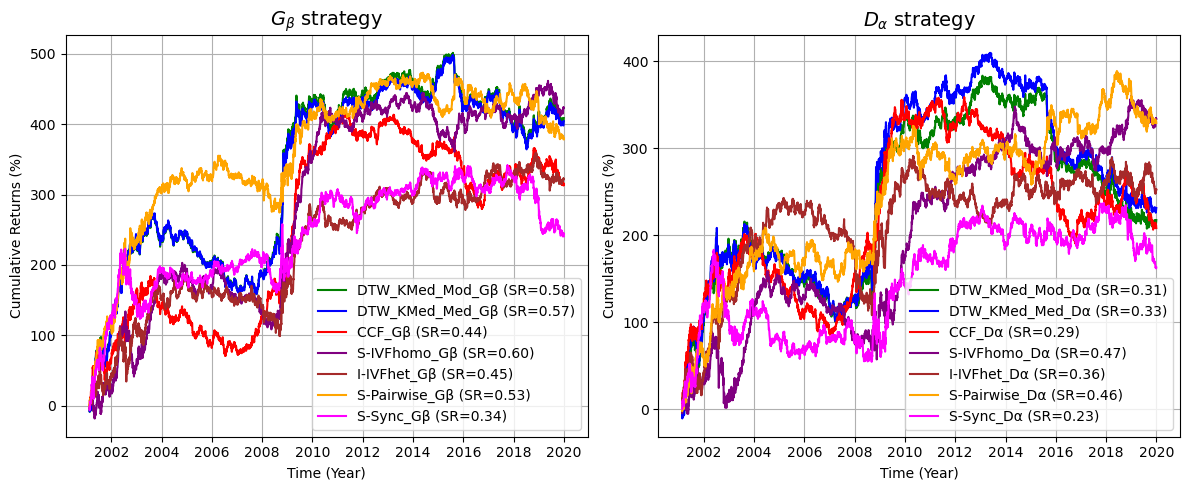


Gβ Strategy Metrics
                 Sharpe Ratio  Sortino Ratio  Calmar Ratio  Hit Rate
name                                                                
DTW_KMed_Mod_Gβ         0.576          0.864         0.164     0.509
DTW_KMed_Med_Gβ         0.569          0.852         0.160     0.510
CCF_Gβ                  0.442          0.655         0.122     0.512
S-IVFhomo_Gβ            0.596          0.872         0.238     0.514
I-IVFhet_Gβ             0.453          0.664         0.196     0.513
S-Pairwise_Gβ           0.533          0.791         0.213     0.508
S-Sync_Gβ               0.339          0.484         0.127     0.507

Dα Strategy Metrics
                 Sharpe Ratio  Sortino Ratio  Calmar Ratio  Hit Rate
name                                                                
DTW_KMed_Mod_Dα         0.306          0.454         0.066     0.500
DTW_KMed_Med_Dα         0.326          0.483         0.067     0.506
CCF_Dα                  0.293          0.428         0.066   

In [157]:
# ------------------ CARGAR RESULTADOS ------------------
with open("trading_results_with_spairwise_ssync.pkl", "rb") as f:
    results_gb, results_da = pickle.load(f)

# ------------------ COLORES ------------------
colors = {
    "CCF": "red",
    "DTW_KMed_Mod": "green",
    "DTW_KMed_Med": "blue",
    "S-Pairwise": "orange",
    "S-Sync": "magenta",
    "S-IVFhomo": "purple",
    "I-IVFhet": "brown",
    "SPY": "black"
}

# ------------------ GRÁFICAS ------------------
plt.figure(figsize=(12, 5))

# Gβ
plt.subplot(1, 2, 1)
for res in results_gb:
    base_name = res["name"].replace("_Gβ", "")
    color = colors.get(base_name, "gray")
    y = res["cum_pnl"]
    x = ts_df.index[-len(y):]
    plt.plot(x, y, label=f"{res['name']} (SR={res['Sharpe Ratio']:.2f})", color=color)
plt.title(r"$G_{\beta}$ strategy", fontsize=14)
plt.xlabel("Time (Year)")
plt.ylabel("Cumulative Returns (%)")
plt.legend()
plt.grid(True)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))

# Dα
plt.subplot(1, 2, 2)
for res in results_da:
    base_name = res["name"].replace("_Dα", "")
    color = colors.get(base_name, "gray")
    y = res["cum_pnl"]
    x = ts_df.index[-len(y):] 
    plt.plot(x, y, label=f"{res['name']} (SR={res['Sharpe Ratio']:.2f})", color=color)
plt.title(r"$D_{\alpha}$ strategy", fontsize=14)
plt.xlabel("Time (Year)")
plt.ylabel("Cumulative Returns (%)")
plt.legend()
plt.grid(True)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))

plt.tight_layout()
plt.show()

# ------------------ TABLAS DE MÉTRICAS ------------------
def print_metrics_table(results, title):
    print(f"\n{title}")
    df = pd.DataFrame([{
        k: round(v, 3) if isinstance(v, float) else v
        for k, v in r.items()
        if k in ["name", "Sharpe Ratio", "Sortino Ratio", "Calmar Ratio", "Hit Rate"]
    } for r in results])
    df.set_index("name", inplace=True)
    print(df)

print_metrics_table(results_gb, "Gβ Strategy Metrics")
print_metrics_table(results_da, "Dα Strategy Metrics")